# **Fraud Detection in Electricity Consumption: A Machine Learning Approach for Tunisia**

## **Introduction**

**Problem Description**

Electricity fraud - including meter tampering, illegal connections, or false billing - constitutes a form of non-technical loss (NTL) that undermines the integrity of the power supply system. In the context of Société Tunisienne de l'Electricité et du Gaz (STEG)'s service across Tunisia, fraudulent consumption distorts actual usage statistics, reduces revenue for the utility, and shifts the financial burden onto honest customers. By proactively identifying which customers are likely fraudulent based on their invoice and consumption history, utility providers can reduce losses, deter illegal practices, and improve fairness and reliability across the network.


Worldwide, electricity theft and other forms of non-technical losses represent a major challenge for utilities. According to [Gresoi et al], electricity theft can account for as much as 8-15% of total electricity distributed in developing countries. Such losses not only degrade the profitability and financial sustainability of utility companies, but also impair grid stability, complicate load planning, and degrade service quality — burdens that often end up being passed to honest users via higher bills or degraded service. Additionally, traditional detection relies on manual inspections and audits, which are often labor-intensive, costly, and inefficient [endesa.com].
In the Tunisian context, with a large customer base and heterogeneous consumption patterns (residential, industrial, urban, rural), systematically identifying fraud through manual inspection is impractical. The scale, economic impact, and fairness implications make this an important problem for STEG and for energy equity across the population.


**Why Machine Learning (ML) is appropriate here**

There are multiple reasons why ML is well suited to detect fraudulent consumption patterns. Firstly, the problem can be formalized as a supervised classification task (fraudulent vs. legitimate clients), using historical billing/consumption data as features and known fraud labels as ground truth. Secondly, modern utilities collect large-scale data (billing history, consumption, location, customer category, meter metadata), which allows ML algorithms to learn complex patterns that may not be evident via simple rules or thresholds. Thirdly, ML enables automated, scalable, and data-driven detection - far more efficient than manual inspection - and can adapt to evolving fraud strategies (meter tampering, disguised overuse, irregular billing). Lastly, the dataset size (on the order of tens or hundreds of thousands of customers or billing histories) provides sufficient data to train robust models and generalize to unseen customers.

Given these points, ML promises higher detection rates, fewer false positives/negatives, and better resource allocation (i.e., inspections targeted where ML flags high-risk customers). Indeed, prior studies have demonstrated that ML-based theft detection models significantly outperform traditional inspection-based methods. [Gresoi et al, 2025]

**Formal ML definition of the task**

* Task type: Supervised binary classification.
* Input: Two datasets. In `invoice`, for each customer, a vector of features derived from their billing and consumption history, meter metadata. In `client`, for each customer, vector of features that include client location, category and fraud label.
* Output: A binary label - fraudulent (1) or legitimate (0).
* Dataset size: A large-scale dataset provided by STEG, covering billing histories for customers across Tunisia, with attribute sets capturing consumption, meter data, client info, and fraud labels.

Thus, the goal is to learn a function that takes the input X and output 0 or 1, where X is the feature space of client/billing attributes, that accurately predicts whether a given customer is committing electricity (or gas) fraud.

**Key Objectives**
* Baseline model: Build a first supervised-learning baseline (in logistic regression) to distinguish fraudulent vs legitimate customers.
* Performance improvement: Experiment with feature engineering, model selection (e.g., more advanced ML models), hyperparameter tuning and cross-validation — to improve detection accuracy, precision, recall, and reduce false positives and negatives.
* Interpretability & Insight: Analyze which features (e.g., abrupt consumption drops/rises, location, meter metadata) are most predictive of fraud. Provide interpretable insights to STEG, which can guide auditing/investigation and policy.
* Practicality & Deployment Considerations: Assess the viability of deploying the model in a real-world pipeline, e.g., for periodic scoring of clients, prioritizing inspections, and integrating with operational workflows.

**Scope (what we will do & what we will not do)**

In scope:
* Use the STEG-provided billing/consumption dataset (customer location & category; meter/counter information; consumption readings; fraud label) to build and evaluate ML classification models.
* Perform exploratory data analysis (EDA), feature engineering, model building (baseline and advanced), hyperparameter tuning, performance evaluation (accuracy, precision, recall, AUC, etc.), and interpretability analysis.
* Provide recommendations such as feature importance, further improvement.

Out of scope (for this report):
* We will not attempt to redesign or deploy new hardware (e.g., “smart meter + double-metering” systems) or physical inspection protocols. While hardware-based or real-time monitoring solutions exist, they are beyond the scope of this data-driven, retrospective analysis.
* We will not handle real-time streaming or live meter data — analysis will be limited to the historical billing / consumption dataset provided.
* We do not guarantee detection of all fraud cases (especially novel or adversarial ones) — the model will likely miss some cases, and could generate false positives/negatives; any flagged cases should be followed up with inspection or verification.


**Why This Work Matters**

Electricity fraud (a form of non-technical loss) remains a major challenge globally [Khan et al, 2020]. ML-based detection systems present a scalable, cost-effective alternative to manual inspection, offering the potential to significantly reduce losses, protect revenue, and improve grid reliability. By applying these techniques to the Tunisian context - using real billing data from STEG - this project aims to deliver actionable insights tailored to Tunisia's energy landscape. In doing so, it could contribute to fairer billing, more efficient resource allocation, and ultimately to strengthening the integrity and sustainability of the national power grid.

## **Importing Data and Libraries**

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

Importing the dataset. We decide to import the training data as the testing data do not contain any labels.

In [ ]:
import kagglehub
path = kagglehub.dataset_download("mrmorj/fraud-detection-in-electricity-and-gas-consumption")
invoice_original = pd.read_csv(path + "/invoice_train.csv")
client_original = pd.read_csv(path + "/client_train.csv")

100%|██████████| 87.2M/87.2M [00:03<00:00, 25.5MB/s]

Extracting files...



/tmp/ipython-input-3341816699.py:3: DtypeWarning: Columns (4) have mixed types. Specify dtype option on import or set low_memory=False.
  invoice_original = pd.read_csv(path + "/invoice_train.csv")


Show the first few entries for `invoice_original`.

In [ ]:
# invoice_original dataset
invoice_original.head()

,client_id,invoice_date,tarif_type,counter_number,counter_statue,counter_code,reading_remarque,counter_coefficient,consommation_level_1,consommation_level_2,consommation_level_3,consommation_level_4,old_index,new_index,months_number,counter_type
0,train_Client_0,2014-03-24,11,1335667,0,203,8,1,82,0,0,0,14302,14384,4,ELEC
1,train_Client_0,2013-03-29,11,1335667,0,203,6,1,1200,184,0,0,12294,13678,4,ELEC
2,train_Client_0,2015-03-23,11,1335667,0,203,8,1,123,0,0,0,14624,14747,4,ELEC
3,train_Client_0,2015-07-13,11,1335667,0,207,8,1,102,0,0,0,14747,14849,4,ELEC
4,train_Client_0,2016-11-17,11,1335667,0,207,9,1,572,0,0,0,15066,15638,12,ELEC


Show the first few entries for `client_original`.

In [ ]:
# client_original dataset
client_original.head()

,disrict,client_id,client_catg,region,creation_date,target
0,60,train_Client_0,11,101,31/12/1994,0.0
1,69,train_Client_1,11,107,29/05/2002,0.0
2,62,train_Client_10,11,301,13/03/1986,0.0
3,69,train_Client_100,11,105,11/07/1996,0.0
4,62,train_Client_1000,11,303,14/10/2014,0.0


Show the number of rows and columns in `invoice_original` and `client_original`.

In [ ]:
print(invoice_original.shape)
print(client_original.shape)

(4476749, 16)
(135493, 6)


Information on the `invoice_original` dataset.

In [ ]:
invoice_original.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4476749 entries, 0 to 4476748
Data columns (total 16 columns):
 #   Column                Dtype 
---  ------                ----- 
 0   client_id             object
 1   invoice_date          object
 2   tarif_type            int64 
 3   counter_number        int64 
 4   counter_statue        object
 5   counter_code          int64 
 6   reading_remarque      int64 
 7   counter_coefficient   int64 
 8   consommation_level_1  int64 
 9   consommation_level_2  int64 
 10  consommation_level_3  int64 
 11  consommation_level_4  int64 
 12  old_index             int64 
 13  new_index             int64 
 14  months_number         int64 
 15  counter_type          object
dtypes: int64(12), object(4)
memory usage: 546.5+ MB


Information on the `client_original` dataset.

In [ ]:
client_original.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 135493 entries, 0 to 135492
Data columns (total 6 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   disrict        135493 non-null  int64  
 1   client_id      135493 non-null  object 
 2   client_catg    135493 non-null  int64  
 3   region         135493 non-null  int64  
 4   creation_date  135493 non-null  object 
 5   target         135493 non-null  float64
dtypes: float64(1), int64(3), object(2)
memory usage: 6.2+ MB


## **Data Cleaning**

We will duplicate the dataset to ensure that the original is not modified.

In [ ]:
invoice = invoice_original.copy()
client = client_original.copy()

We will rename some of the feature's name for better clarity.

In [ ]:
invoice = invoice.rename(columns={
    'counter_statue': 'counter_status',
    'reading_remarque': 'reading_remark'
})

Formatting of datetime columns.

In [ ]:
# convert invoice_date and creation_date to datetime format

invoice['invoice_date'] = pd.to_datetime(invoice['invoice_date'])
client['creation_date'] = pd.to_datetime(client['creation_date'])

/tmp/ipython-input-1835004410.py:4: UserWarning: Parsing dates in %d/%m/%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  client['creation_date'] = pd.to_datetime(client['creation_date'])


In `invoice`, the `invoice_date` is not in chronological order. It needs to be sorted while ensuring the `client_id` still remains grouped together.

In [ ]:
invoice = invoice.sort_values(by=['client_id', 'invoice_date'])
invoice.head()

,client_id,invoice_date,tarif_type,counter_number,counter_status,counter_code,reading_remark,counter_coefficient,consommation_level_1,consommation_level_2,consommation_level_3,consommation_level_4,old_index,new_index,months_number,counter_type
22,train_Client_0,2005-10-17,11,1335667,0,203,6,1,124,0,0,0,3685,3809,4,ELEC
23,train_Client_0,2006-02-24,11,1335667,0,203,6,1,141,0,0,0,3809,3950,4,ELEC
24,train_Client_0,2006-06-23,11,1335667,0,203,6,1,162,0,0,0,3950,4112,4,ELEC
25,train_Client_0,2006-10-18,11,1335667,0,203,6,1,159,0,0,0,4112,4271,4,ELEC
28,train_Client_0,2007-02-26,11,1335667,0,203,6,1,182,0,0,0,4271,4453,4,ELEC


Checking for any missing values in the data.

In [ ]:
invoice.isna().sum()

,0
client_id,0
invoice_date,0
tarif_type,0
counter_number,0
counter_status,0
counter_code,0
reading_remark,0
counter_coefficient,0
consommation_level_1,0
consommation_level_2,0


In [ ]:
client.isna().sum()

,0
disrict,0
client_id,0
client_catg,0
region,0
creation_date,0
target,0


From the code, there are no missing values in `invoice` and `client` dataset.

Next, we check if the data contains any duplicate rows.

In [ ]:
print("\nNumber of duplicate rows in `client`:", client.duplicated().sum())
print("\nNumber of duplicate rows in `invoice`:", invoice.duplicated().sum())


Number of duplicate rows in `client`: 0

Number of duplicate rows in `invoice`: 11


There are no duplicate rows in `client` but there are 11 duplicate rows in `invoice`. We assume that the duplicate rows in `invoice` are the result of data entry error and omit them.

In [ ]:
# drop duplicate rows

invoice = invoice.drop_duplicates()

print("\nNumber of duplicate rows in `invoice`:", invoice.duplicated().sum())


Number of duplicate rows in `invoice`: 0


From https://www.kaggle.com/code/michaelhosseini/data-preparation/notebook, we identified a specific data corruption issue documented by Michael Hosseini regarding the counter_coefficient column. This corruption arises because a misplaced decimal point shifts values across adjacent numeric columns, resulting in inconsistent magnitudes and implausible consumption readings. Consequently, repairing or discarding these rows is required to avoid spurious fraud patterns. Additionally, we addressed the counter_status field, which mixes numeric codes and string categories; following standard cleaning procedures for this dataset, we standardized these into a common categorical type to ensure consistent feature engineering.



This is the following information on the `client` dataset:
* `disrict`: District where the client is
* `client_id`: Unique id for client
* `client_catg`: Category client belongs to
* `region`: Area where the client is
* `creation_date`: Date client joined
* `target`: 1 means fraud, 0 means not fraud

This is the following information on the `invoice` dataset:
* `client_id`: Unique id for client
* `invoice_date`: Date of the invoice
* `tarif_type`: Type of tax (coded in number)
* `counter_number`: number (should be unique to each client)
* `counter_status`: takes up to 5 values such as working, not working, on hold status etc
* `counter_code`: code
* `reading_remark`: notes that the STEG agent takes during his visit to the cleint (e.g.: if the counter shows something wrong etc)
* `counter_coefficient`: An additional coefficient to be added when standard consumption is exceeded
* `consommation_level_1`: Consumption_level_1
* `consommation_level_2`: Consumption_level_2
* `consommation_level_3`: Consumption_level_3
* `consommation_level_4`: Consumption_level_4
* `old_index`: Old index (of invoice)
* `new_index`: New index (of invoice)
* `months_number`: Month number (between invoices)
* `counter_type`: Type of counter. "ELEC" for electricity, "GAZ" for gas





### Data Corruption

From https://www.kaggle.com/code/michaelhosseini/data-preparation/notebook, there is a hint of data corruption. With more than 4 million entries, I think we can remove them and it should not severely impact the performance of the model.

When we are importing the `invoice` data, there was a warning on column 4 ('counter_status') which has mixed data type. Checking, it contains both int and str.

In [ ]:
# find inconsistent counter_status data

invoice['counter_status'].value_counts()

,count
counter_status,
0,4346960
1,73496
0,32048
5,20484
4,2706
1,540
3,258
5,144
2,32


In [ ]:
list(invoice['counter_status'].unique())

[0, 1, 5, 4, 3, 2, 769, '0', '5', '1', '4', 'A', 618, 269375, 46, 420]

It is assumed that 'counter_status' should contain the numbers from 0 to 5. Unusual numbers (769, 618, 269375, 46, 420, 'A') possibly indicate parsing issue. (What the above link suggest). We will delete these rows based on the client_id to keep it simple.

In [ ]:
# remove rows with counter_statue data that is inconsistent

remove = [769, 618, 269375, 46, 420, 'A']
invoice = invoice[~invoice['counter_status'].isin(remove)]

One identified issue is assumed to be caused by 'counter_coefficient' having had a decimal place that caused an offset in columns. This was deduced by suspicious 'months_number' and 'consommation_level_2' values originally.

For example, "1,5" would cause the "5" to fall into 'consommation_level_1', etc. 'months_number' was then overwritten and lost.
'counter_coefficient' would therefore need to be reconstructed for these examples, and columns shifted.

According to the analysis of this notebook [https://www.kaggle.com/code/michaelhosseini/data-preparation/notebook], rows have to be filtered carefully to identify only those related to the described data corruption problem:

If(0 < 'consommation_level_1' < 10), then flag.
*   On the assumption it is single decimal place, it must be a single
*   All other conditions are applied after this.

If('consommation_level_2' > 0) or If('months_number' > 240), then flag.
*   The minimum monthly cap seen is 50, so 'consommation_level_2' should not be used prior to that.
*   This would not apply if only true 'consommation_level_1' was used, so is insufficient.
*    'months_number' would not reasonably exceed 20 years.

In [ ]:
mask = (((invoice['consommation_level_1'] > 0) & (invoice['consommation_level_1'] < 10)) &
        ((invoice['consommation_level_2'] != 0)) | (invoice['months_number'] > 240))
pd.concat([invoice[~mask].head(5), invoice[mask].head(5)])

,client_id,invoice_date,tarif_type,counter_number,counter_status,counter_code,reading_remark,counter_coefficient,consommation_level_1,consommation_level_2,consommation_level_3,consommation_level_4,old_index,new_index,months_number,counter_type
22,train_Client_0,2005-10-17,11,1335667,0,203,6,1,124,0,0,0,3685,3809,4,ELEC
23,train_Client_0,2006-02-24,11,1335667,0,203,6,1,141,0,0,0,3809,3950,4,ELEC
24,train_Client_0,2006-06-23,11,1335667,0,203,6,1,162,0,0,0,3950,4112,4,ELEC
25,train_Client_0,2006-10-18,11,1335667,0,203,6,1,159,0,0,0,4112,4271,4,ELEC
28,train_Client_0,2007-02-26,11,1335667,0,203,6,1,182,0,0,0,4271,4453,4,ELEC
20214,train_Client_100551,2009-03-09,11,1099471,0,467,9,1,5,1200,3024,0,0,495,3311,ELEC
20219,train_Client_100551,2009-11-05,11,1099471,0,467,6,1,5,229,0,0,0,342,495,ELEC
20212,train_Client_100551,2010-06-05,11,1099471,0,467,9,1,5,1200,10566,0,0,9971,17815,ELEC
20213,train_Client_100551,2010-08-01,11,1099471,0,467,9,1,5,1200,8790,0,0,3311,9971,ELEC
20211,train_Client_100551,2010-08-30,11,1099471,0,467,6,1,5,1200,10744,0,0,17815,25778,ELEC


To keep it simple, we will remove these problematic rows as they seem unreliable and troublesome to clean them.

In [ ]:
invoice = invoice[~mask]
invoice.shape

(4475299, 16)

The number of rows went down from 4476749 to 4475299 which is pretty negligible so it should not have a huge impact on the remaining data.

**However, we would acknowledge that it is possible there are other data corruption we may not carefully handle, thus impacting the accuracy of our models.**

## Exploratory Data Analysis (Basic)

The goal of this section is to explore the features in `invoice` and `client`.



---



First, we want to know the percentage of people who commit fraud versus those who do not commit fraud by plotting a bar plot.

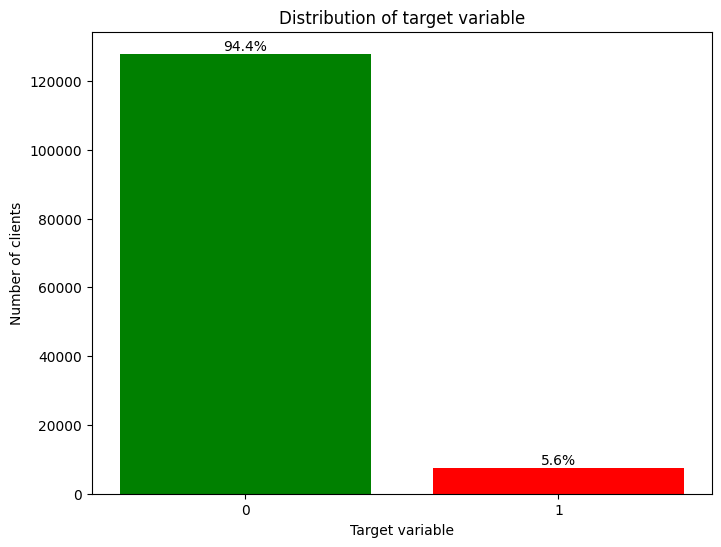

In [ ]:
counts = client.groupby(['target'])['client_id'].count()
percentages = [100 * count / sum(counts) for count in counts]

colors = ['green', 'red']
fig, ax = plt.subplots(figsize=(8, 6))
ax.bar(x=['0', '1'], height=counts.values, color=colors)

ax.set_xlabel('Target variable')
ax.set_ylabel('Number of clients')
ax.set_title('Distribution of target variable')

for i, v in enumerate(percentages):
    ax.text(i, counts.values[i]+1000, f'{v:.1f}%', ha='center')

plt.show()

From the bar plot, we can observe that 94.4% of the clients do not commit fraud while the other 5.6% commit fraud. It makes sense that only a small minority of people will commit fraud. This means that the class is severely imbalanced and care needs to be taken against this imbalanced dataset. (Later we will argue why we would not be using SMOTE).



---



Next, we want to observe if there is any region in which the percentage of fraud is higher than the national average.

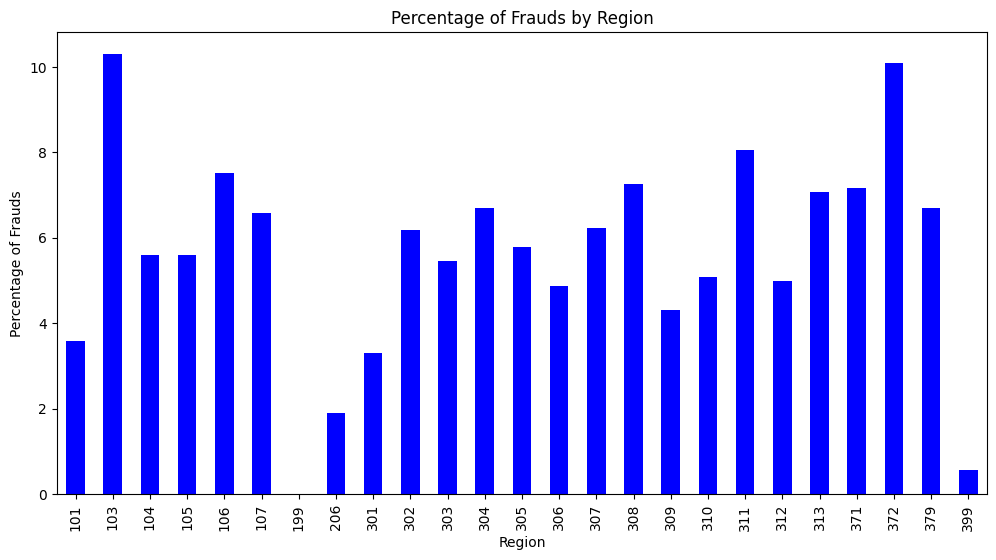

In [ ]:
fraud_pct = client.groupby("region")["target"].mean() * 100

fig, ax = plt.subplots(figsize=(12, 6))
fraud_pct.plot(kind="bar", ax=ax, color="blue")
ax.set_xlabel("Region")
ax.set_ylabel("Percentage of Frauds")
ax.set_title("Percentage of Frauds by Region")
plt.show()

From the bar plot, regions 103 and 372 have the highest percentage of fraud compared to other regions, while regions 199 and 399 have a much lower fraud rate as compared to the average (5.6%).



---



Additionally, we also explore more on the percentage of frauds by district.

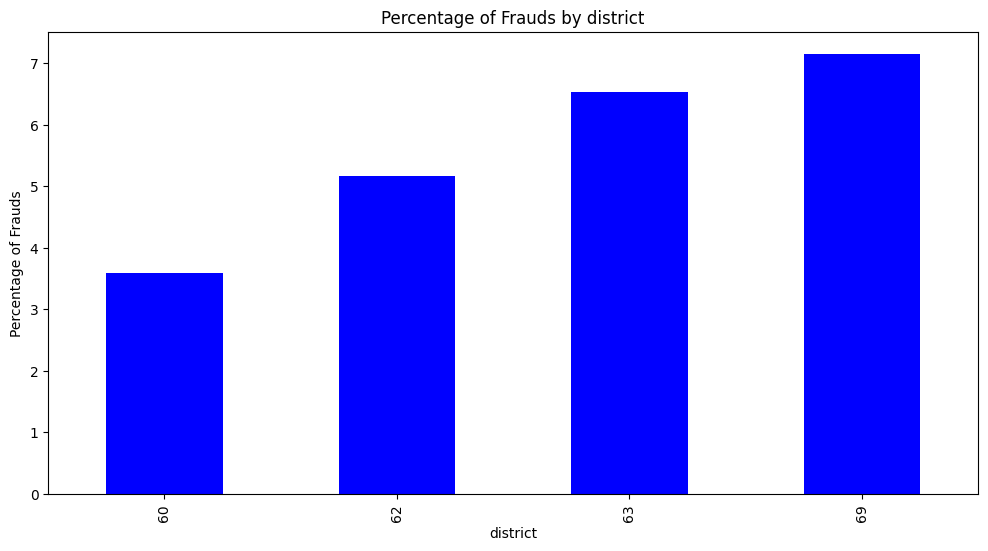

In [ ]:
fraud_pct = client.groupby("disrict")["target"].mean() * 100

fig, ax = plt.subplots(figsize=(12, 6))
fraud_pct.plot(kind="bar", ax=ax, color="blue")
ax.set_xlabel("district")
ax.set_ylabel("Percentage of Frauds")
ax.set_title("Percentage of Frauds by district")
plt.show()

We noticed that district 69 has the highest percentage of fraud, while district 60 has the lowest percentage of fraud. Hence, `district` and `region` seems to be important features in detecting if a client may commit fraud.

---



Furthermore, we explore the percentage of frauds by client category.

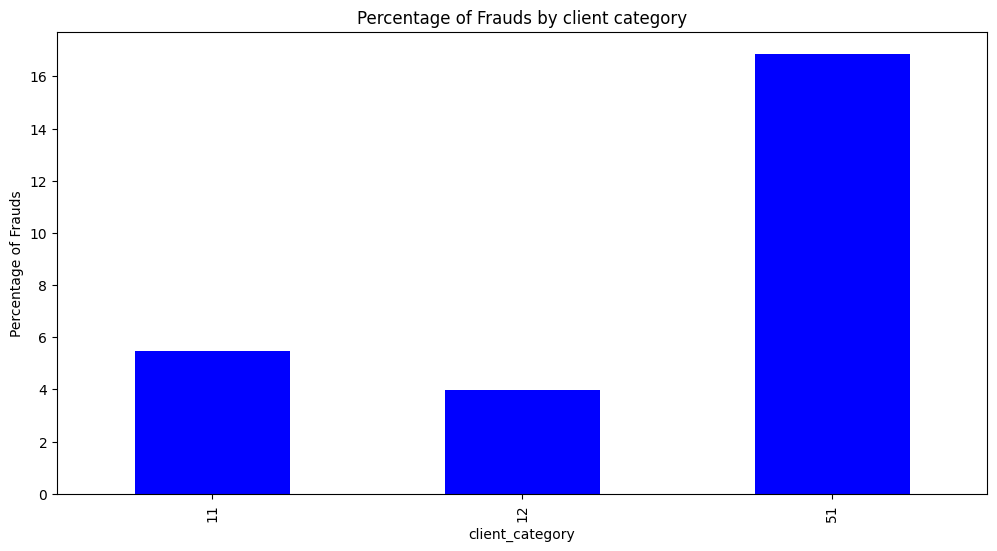

In [ ]:
fraud_pct = client.groupby("client_catg")["target"].mean() * 100

fig, ax = plt.subplots(figsize=(12, 6))
fraud_pct.plot(kind="bar", ax=ax, color="blue")
ax.set_xlabel("client_category")
ax.set_ylabel("Percentage of Frauds")
ax.set_title("Percentage of Frauds by client category")
plt.show()

From the bar plot, we can see that client category of 51 has a significantly higher percentage of fraud as compared to the other two category with more than 16% of clients from category 51 committing fraud. This suggests that `client_catg` is a significant factor in predicting fraud.



---



Additionally, in `counter_type`, there are 2 categories. ELEC for electricity and GAZ for gas.

In [ ]:
invoice['counter_type'].value_counts()

,count
counter_type,
ELEC,3078895
GAZ,1396404


Filter the `invoice` data into `elec` and `gas`. One contains record solely on electricity and the other contains record solely on gas.

In [ ]:
elec = invoice[invoice['counter_type'] == "ELEC"]
gas = invoice[invoice['counter_type'] == "GAZ"]

Show the number of unique clients in each of the invoices.

In [ ]:
print(client['client_id'].nunique())
print(elec['client_id'].nunique())
print(gas['client_id'].nunique())

135493
134796
62039


From above, we noticed that of the 135493 clients using STEG, majority of them (more than 99%) use it for electricity while a small number use it for gas consumption. Since the amount of client that uses gas is small, we justify that we will focus on electricity consumption instead and ignore `gas` for simplicity.

## Data Preprocessing

Combine the 4 levels of consumption into one variable `consumption`.


We aggregate the four levels of consumption into a single feature. This is necessary because the levels represent tiered pricing tranches rather than distinct types of usage. Summing them provides the true total electricity consumption for the billing period, a standard practice in analyzing this dataset

In [ ]:
invoice['consumption'] = invoice['consommation_level_1'] + invoice['consommation_level_2'] + invoice['consommation_level_3'] + invoice['consommation_level_4']
invoice = invoice.drop(columns=['consommation_level_1', 'consommation_level_2', 'consommation_level_3', 'consommation_level_4'])

Separate into electricity and gas.

We focused our analysis on the dominant energy type (electricity) and merged low-frequency categorical levels. Energy-fraud studies often isolate the dominant energy type to simplify modeling and avoid unstable estimates derived from extremely small subgroups. The imbalance learning literature notes that rare categorical levels introduce high variance; therefore, analyzing the majority usage type separately improves model stability.

In [ ]:
elec = invoice[invoice['counter_type'] == "ELEC"]
gas = invoice[invoice['counter_type'] == "GAZ"]

We introduce a `days_since_last` feature to capture temporal irregularities. Fraudulent clients often manipulate meter reading schedules to hide consumption spikes, leading to irregular gaps between invoices. Calculating the time difference helps normalize consumption data against the billing duration.

In [ ]:
elec = elec.sort_values(["client_id", "invoice_date"]) # sort by ascending `client id` and `invoice_date`
elec["days_since_last"] = elec.groupby("client_id")["invoice_date"].diff().dt.days # add a new column `days_since_last` to find
                                                                                   #    the number of days since the previous invoice

Adding an `avg_daily_consumption` column to find the average daily consumption for an invoice. This needs to be adjusted to daily consumption as an invoice with higher `day_since_last` will usually mean more electrical consumption. We need to average them to prevent this misleading trend to be a factor in identifying fraud.

In [ ]:
elec["avg_daily_consumption"] = elec['consumption'] / elec['days_since_last']

Aggregate features per client.

The reason for creating these time-based aggregations as the `invoice` data shows the time record (of invoices) for each client. In a sense, this data is similar to a time-based series data. To make the data as tabular (the model we are planning to develop needs to handle tabular data), we decide to use time-based aggregations, which uses statistic such as mean, standard deviation and max on continuous variables (such as `consumption`, `days_since_last` and `avg_daily_consumption`) to condense all of the invoices into one corresponding number to the client [W08b].

In [ ]:
agg_funcs = {
    "consumption": ["mean", "std", "min"],
    "days_since_last": ["mean", "std", "max"],
    "avg_daily_consumption": ["mean", "std", "max"]
}
## to include all the previous aggregate features as well. The ones we removed.


invoice_features = elec.groupby("client_id").agg(agg_funcs)
invoice_features.columns = ["_".join(col) for col in invoice_features.columns]
invoice_features = invoice_features.reset_index()

A look at `invoice_features`.

In [ ]:
invoice_features

,client_id,consumption_mean,consumption_std,consumption_min,days_since_last_mean,days_since_last_std,days_since_last_max,avg_daily_consumption_mean,avg_daily_consumption_std,avg_daily_consumption_max
0,train_Client_0,362.971429,341.553930,38,144.147059,87.601070,508.0,3.568206,5.502266,30.755556
1,train_Client_1,557.540541,197.935960,190,136.472222,92.492312,372.0,10.717684,23.122765,117.250000
2,train_Client_10,836.500000,646.808386,188,289.470588,250.701794,738.0,4.309229,2.377439,9.400000
3,train_Client_100,1.200000,3.607011,0,140.210526,95.569974,442.0,0.009884,0.029847,0.121951
4,train_Client_1000,922.642857,633.485669,124,121.923077,80.057752,301.0,50.407931,106.453032,310.750000
...,...,...,...,...,...,...,...,...,...,...
134791,train_Client_99995,0.000000,0.000000,0,141.638889,46.615235,250.0,0.000000,0.000000,0.000000
134792,train_Client_99996,311.250000,226.889464,3,121.421053,45.829777,231.0,4.617709,7.557098,29.583333
134793,train_Client_99997,405.000000,164.270683,280,134.333333,99.681158,395.0,15.447998,32.593951,128.666667
134794,train_Client_99998,370.500000,232.638131,206,122.000000,NaN,122.0,1.688525,NaN,1.688525


Filter `client` into `client_tab` (clients that uses electricity only)

In [ ]:
client_tab = client[client['client_id'].isin(elec['client_id'])]

Merge with `invoice_features` data

In [ ]:
data_baseline = client_tab.merge(invoice_features, on="client_id", how="left")

data_baseline

,disrict,client_id,client_catg,region,creation_date,target,consumption_mean,consumption_std,consumption_min,days_since_last_mean,days_since_last_std,days_since_last_max,avg_daily_consumption_mean,avg_daily_consumption_std,avg_daily_consumption_max
0,60,train_Client_0,11,101,1994-12-31,0.0,362.971429,341.553930,38,144.147059,87.601070,508.0,3.568206,5.502266,30.755556
1,69,train_Client_1,11,107,2002-05-29,0.0,557.540541,197.935960,190,136.472222,92.492312,372.0,10.717684,23.122765,117.250000
2,62,train_Client_10,11,301,1986-03-13,0.0,836.500000,646.808386,188,289.470588,250.701794,738.0,4.309229,2.377439,9.400000
3,69,train_Client_100,11,105,1996-07-11,0.0,1.200000,3.607011,0,140.210526,95.569974,442.0,0.009884,0.029847,0.121951
4,62,train_Client_1000,11,303,2014-10-14,0.0,922.642857,633.485669,124,121.923077,80.057752,301.0,50.407931,106.453032,310.750000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
134791,62,train_Client_99995,11,304,2004-07-26,0.0,0.000000,0.000000,0,141.638889,46.615235,250.0,0.000000,0.000000,0.000000
134792,63,train_Client_99996,11,311,2012-10-25,0.0,311.250000,226.889464,3,121.421053,45.829777,231.0,4.617709,7.557098,29.583333
134793,63,train_Client_99997,11,311,2011-11-22,0.0,405.000000,164.270683,280,134.333333,99.681158,395.0,15.447998,32.593951,128.666667
134794,60,train_Client_99998,11,101,1993-12-22,0.0,370.500000,232.638131,206,122.000000,NaN,122.0,1.688525,NaN,1.688525


One hot encoding, since `disrict`, `region` and `client_catg` are all categorical features. This way, our baseline model (logistic regression) can handle these features.

In [ ]:
data_baseline = pd.get_dummies(data_baseline, columns=["disrict", "region", "client_catg"], drop_first=True)

Information on `data_baseline` that we will use on baseline model (logistic regression).

In [ ]:
data_baseline.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 134796 entries, 0 to 134795
Data columns (total 40 columns):
 #   Column                      Non-Null Count   Dtype         
---  ------                      --------------   -----         
 0   client_id                   134796 non-null  object        
 1   creation_date               134796 non-null  datetime64[ns]
 2   target                      134796 non-null  float64       
 3   consumption_mean            134796 non-null  float64       
 4   consumption_std             129783 non-null  float64       
 5   consumption_min             134796 non-null  int64         
 6   days_since_last_mean        129783 non-null  float64       
 7   days_since_last_std         124296 non-null  float64       
 8   days_since_last_max         129783 non-null  float64       
 9   avg_daily_consumption_mean  129702 non-null  float64       
 10  avg_daily_consumption_std   114813 non-null  float64       
 11  avg_daily_consumption_max   129702 non-

It looks like there may be some missing data in `data_baseline` after these feature engineering.

In [ ]:
data_baseline.isnull().sum()

,0
client_id,0
creation_date,0
target,0
consumption_mean,0
consumption_std,5013
consumption_min,0
days_since_last_mean,5013
days_since_last_std,10500
days_since_last_max,5013
avg_daily_consumption_mean,5094


For simplicity, we remove any rows that contain missing data. The reason for this is that the missing data belong the time-based aggregations. It does not make sense to replace the missing value with 0 or the mean as it does not come from the actual data - it feels synthetic. Hence, we decide to drop them.

In [ ]:
data_baseline = data_baseline.dropna(how='any', axis=0)

data_baseline.shape

(114813, 40)

The number of clients is reduced from 134796 to 114813, which is not much of a loss.

## Baseline Model - Logistic Regression

The first model we will use is logistic regression, which serves as our baseline model. The reason for choosing logistic regression as our baseline model is that it is a parametric model and is therefore more interpretable than other methods that are non-parametric such as tree-based models.

In [ ]:
from sklearn.model_selection import train_test_split

X = data_baseline.drop(columns=["client_id", "target", "creation_date"])
y = data_baseline["target"]

X_train, X_test, y_train, y_test = train_test_split(X, y, stratify=y, test_size=0.2, random_state=42)

**Why don't we use SMOTE?**

One important note here is that we argued against performing SMOTE on the data, even though our dataset is imbalanced. This is because the `data_baseline` contains binary features such as 'region_103' which gives True if client is in region 103 and False otherwise. SMOTE sometimes struggles to handle this feature and it is impossible to handle interpolate between True and False. Even if we use other variants of SMOTE such as SMOTENC, it is possible that say 'region_103' and 'region_104' is given True from interpolation, which is contradictory as a client can only live in one region. Furthermore, interpolating continuous features such as 'consumption_mean' would be synthetic as it is not from some invoice trend. [https://arxiv.org/pdf/2201.08528]

Thus, we decide to use class_weight = 'balanced' in logistic regression to account for this imbalanced class instead.

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, roc_auc_score

# Weight minority class automatically
logreg = LogisticRegression(class_weight='balanced', max_iter=1000, solver='lbfgs')
logreg.fit(X_train, y_train)

y_pred_log = logreg.predict(X_test)
y_prob_log = logreg.predict_proba(X_test)[:, 1]

print(classification_report(y_test, y_pred_log))
print("AUC:", roc_auc_score(y_test, y_prob_log))

              precision    recall  f1-score   support

         0.0       0.97      0.67      0.79     21714
         1.0       0.09      0.59      0.16      1249

    accuracy                           0.67     22963
   macro avg       0.53      0.63      0.48     22963
weighted avg       0.92      0.67      0.76     22963

AUC: 0.6759118264492778


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Show the confusion matrix of logistic regression.

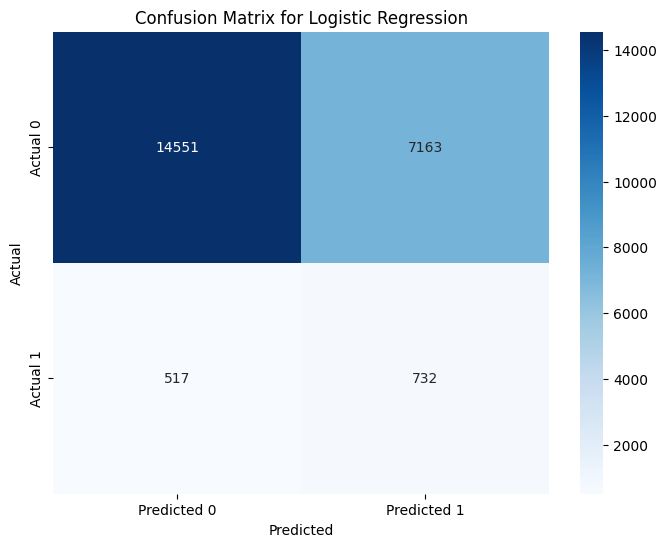

In [ ]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred_log)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=['Predicted 0', 'Predicted 1'],
            yticklabels=['Actual 0', 'Actual 1'])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix for Logistic Regression")
plt.show()

Evaluation metrics on logistic regression.

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score

accuracy = accuracy_score(y_test, y_pred_log)
precision = precision_score(y_test, y_pred_log)
recall = recall_score(y_test, y_pred_log)

print(f"Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")

Accuracy: 0.6655
Precision: 0.0927
Recall: 0.5861


Calculating the PR AUC of logistic regression.

In [ ]:
from sklearn.metrics import precision_recall_curve, auc

precision, recall, thresholds = precision_recall_curve(y_test, y_prob_log)

auc_score = auc(recall, precision)
print('Logistic PR AUC: %.3f' % auc_score)

Logistic PR AUC: 0.104


Displaying the PR Curve for logistic regression.

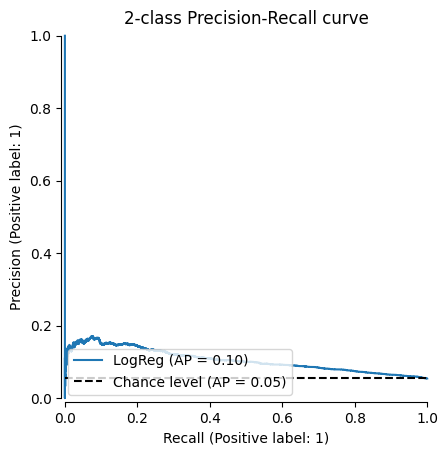

In [ ]:
from sklearn.metrics import PrecisionRecallDisplay

display = PrecisionRecallDisplay.from_predictions(
    y_test, y_prob_log, name="LogReg", plot_chance_level=True, despine=True
)
_ = display.ax_.set_title("2-class Precision-Recall curve")

From the baseline model of logistic regression:

Accuracy | Precision | Recall | ROC AUC | PR AUC
-------- | -------- | -------- | -------- | --------
0.6655 | 0.0927 | 0.5861 | 0.6759 | 0.104


**Metrics**

Accuracy is not the best metrics to use as it is misleading in an imbalanced dataset. As previously mentioned, around 5% of clients commit fraud so a naive model can just predict not fraud and get an accuracy of 95%.

Precision and recall are much better metrics to use in imbalanced dataset but in our case, recall is more important than precision. This is because we set up confusion matrix such that frauds are labelled as positive while non-frauds are labelled as negative. From Lecture [07b], we learnt that

Precision = $\frac{TP}{TP + FP}$. Recall = $\frac{TP}{TP + FN}$.

In our case, false negative is more important than false positive as failing to catch a fraudster is more catastrophic than accusing someone of being a fraudster. Of course, we should not accuse too many people of being a fraudster but having a higher recall is more crucial than a high precision.

However, precision and recall usually depends on the threshold. By default, a client with a probability of more than 50% is classified as fraud while client with probability less than 50% is classified as non-fraud. If we want to improve recall, we can set the threshold lower (say 30%) so that there is fewer false negative, albeit worsening precision. To compare between models, we can use the metric Receiver Operating Characteristic Area-Under-Curve (ROC-AUC) and Precision-Recall Area-Under-Curve (PR-AUC). From Lecture [07b] (and https://machinelearningmastery.com/roc-curves-and-precision-recall-curves-for-imbalanced-classification/), ROC-AUC is not a good metrics against imbalanced dataset as it can be misleading. A more appropriate metric would be PR-AUC, which is more robust in imbalanced dataset. The baseline model achieved a PR-AUC of 0.104, which is better than the chance level of 0.05, meaning it perform twice as better than random chance. However, a PR-AUC of 0.104 still remains pretty poor.

Find which features is the most important in baseline logistic regression.

In [ ]:
import pandas as pd
feature_importance = pd.DataFrame({
    'feature': X.columns,
    'coef': logreg.coef_[0]
}).sort_values(by='coef', ascending=False)

In [ ]:
feature_importance

,feature,coef
12,region_103,0.763254
11,disrict_69,0.562678
10,disrict_63,0.477384
36,client_catg_51,0.439187
28,region_311,0.410712
9,disrict_62,0.390652
21,region_304,0.284641
31,region_371,0.249588
32,region_372,0.190830
24,region_307,0.187170


From `feature_importance` we can observe that 'region_103' has the highest positive coefficient of 0.763 while 'disrict_69' has the second highest of 0.563. As the model is using region 101, disrict 60 and client_catg 11 as the baseline, it suggests that people from region_103 or district_69 are probably more likely to commit fraud. This is further supported from the EDA section, where we pointed out that people from these areas have a much higher percentage of fraud when compared to other areas.

In contrast, 'region_301' and 'region_104' has the highest negative coefficient of -0.514 and -0.237 respectively. With region_101 as the base, this result is rather perplexing as from the plot, region_104 has a much higher fraud rate than region_101. It may be possible that the fraudster in region_104 have a much normal consumption behaviour which causes the model to have more difficulty in catching them. That might explain for the huge negative coefficient. Region_301 have a lower fraud rate than region_101 so it make sense that people in region_101 will have a smaller probability in committing fraud.

In addition, we suspect that the model is underfitting - it is not flexible enough to handle the complex relationship of detecting fraud.

In [ ]:
logreg = LogisticRegression(class_weight='balanced', max_iter=1000, solver='lbfgs')
logreg.fit(X_train, y_train)

y_pred_log = logreg.predict(X_train)
y_prob_log = logreg.predict_proba(X_train)[:, 1]

print(classification_report(y_train, y_pred_log))
print("AUC:", roc_auc_score(y_train, y_prob_log))

/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


              precision    recall  f1-score   support

         0.0       0.97      0.67      0.79     86854
         1.0       0.10      0.61      0.17      4996

    accuracy                           0.67     91850
   macro avg       0.53      0.64      0.48     91850
weighted avg       0.92      0.67      0.76     91850

AUC: 0.6882563065673484


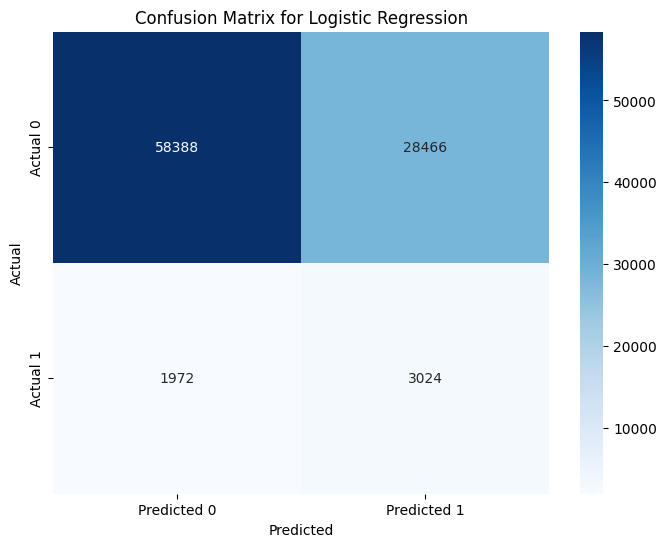

In [ ]:
cm = confusion_matrix(y_train, y_pred_log)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=['Predicted 0', 'Predicted 1'],
            yticklabels=['Actual 0', 'Actual 1'])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix for Logistic Regression")
plt.show()

In [ ]:
accuracy = accuracy_score(y_train, y_pred_log)
precision = precision_score(y_train, y_pred_log)
recall = recall_score(y_train, y_pred_log)

print(f"Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")

Accuracy: 0.6686
Precision: 0.0960
Recall: 0.6053


In [ ]:
precision, recall, thresholds = precision_recall_curve(y_train, y_prob_log)

auc_score = auc(recall, precision)
print('Logistic PR AUC: %.3f' % auc_score)

Logistic PR AUC: 0.108


The metrics and confusion matrix do confirm that our model is underfitting as it exhibits high bias. It has a really high false positive as shown in the confusion matrix and the metrics are similar to the test results (Precision (training) is 0.0960 compared to Precision (testing) of 0.0927, Recall (training) is 0.6053 compared to Recall (testing) of 0.5861).


Therefore, to improve our model's prediction, we have to reduce bias by adding more informative features, considering switching to non-parametric models and also employ boosting models such as XGBoost and LightGBM.

The next section will be our process in improving the model by exploring the data in further detail and perform more feature engineering to improve the PR-AUC of the baseline model.

## Exploratory Data Analysis (in depth)

One flaw in our baseline model is that most of the feature in `elec` were being disregarded as we only use 'consumption' and other newly defined features to train the baseline model. This may explain for the high biasness in our baseline model. If we can include some of these disregarded features such as 'counter_number' or 'reading_remark' into our data, perhaps our model will perform better.



---



First, we perform some analysis on 'counter_number'. From our understanding, 'counter_number' refers to the counter number owned by the client. Each client should have a one unique counter number. However, exploring `elec` further, we noticed some client has multiple counter number, which seems suspicious.

In [ ]:
# create counter_number_uniqueness to find out how many counter numbers a client has
multiple_counter = (
    elec.groupby('client_id')['counter_number']
        .nunique()
        .apply(lambda x: True if x > 1 else False)
        .rename('multiple_counter')
)


# merge into client data
client_tab = client.merge(multiple_counter, on="client_id", how="left")

# merge with invoice_features data
data = client_tab.merge(invoice_features, on="client_id", how="left")

data

,disrict,client_id,client_catg,region,creation_date,target,multiple_counter,consumption_mean,consumption_std,consumption_min,days_since_last_mean,days_since_last_std,days_since_last_max,avg_daily_consumption_mean,avg_daily_consumption_std,avg_daily_consumption_max
0,60,train_Client_0,11,101,1994-12-31,0.0,False,362.971429,341.553930,38.0,144.147059,87.601070,508.0,3.568206,5.502266,30.755556
1,69,train_Client_1,11,107,2002-05-29,0.0,False,557.540541,197.935960,190.0,136.472222,92.492312,372.0,10.717684,23.122765,117.250000
2,62,train_Client_10,11,301,1986-03-13,0.0,False,836.500000,646.808386,188.0,289.470588,250.701794,738.0,4.309229,2.377439,9.400000
3,69,train_Client_100,11,105,1996-07-11,0.0,False,1.200000,3.607011,0.0,140.210526,95.569974,442.0,0.009884,0.029847,0.121951
4,62,train_Client_1000,11,303,2014-10-14,0.0,False,922.642857,633.485669,124.0,121.923077,80.057752,301.0,50.407931,106.453032,310.750000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
135488,62,train_Client_99995,11,304,2004-07-26,0.0,False,0.000000,0.000000,0.0,141.638889,46.615235,250.0,0.000000,0.000000,0.000000
135489,63,train_Client_99996,11,311,2012-10-25,0.0,False,311.250000,226.889464,3.0,121.421053,45.829777,231.0,4.617709,7.557098,29.583333
135490,63,train_Client_99997,11,311,2011-11-22,0.0,False,405.000000,164.270683,280.0,134.333333,99.681158,395.0,15.447998,32.593951,128.666667
135491,60,train_Client_99998,11,101,1993-12-22,0.0,False,370.500000,232.638131,206.0,122.000000,NaN,122.0,1.688525,NaN,1.688525


In [ ]:
data['multiple_counter'].value_counts()

,count
multiple_counter,
False,112200
True,22596


Of the 134796 clients, 22596 of them has multiple counter number.

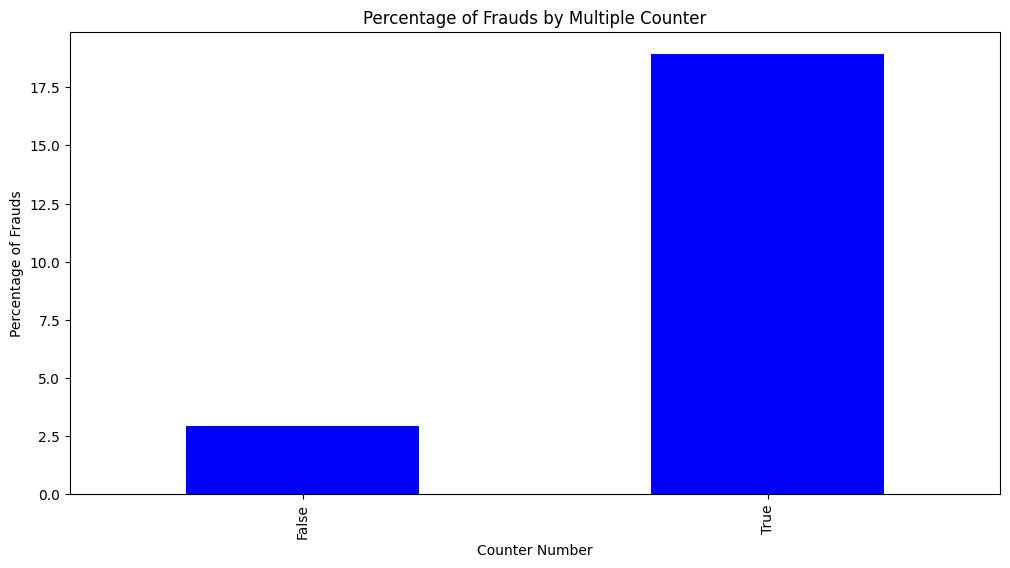

In [ ]:
# Calculate the percentage of frauds by multiple_counter
fraud_pct_counter_number = data.groupby("multiple_counter")["target"].mean() * 100

# Create a bar chart using Matplotlib
fig, ax = plt.subplots(figsize=(12, 6))
fraud_pct_counter_number.plot(kind="bar", ax=ax, color="blue")
ax.set_xlabel("Counter Number")
ax.set_ylabel("Percentage of Frauds")
ax.set_title("Percentage of Frauds by Multiple Counter")
plt.show()

From the plot, we can see a substantial difference in the percentage of fraud between people who have single counter number and people who have multiple counter number. Despite that people who have multiple counter number are the minority group, the percentage of them committing fraud is approximately 18%, which is significantly more as compared to clients with 1 counter only, which is around 2.5%. This may confirm that our hypothesis is potentially correct and this `counter_number_uniqueness` is a really important feature.

We believe this pattern is intuitive. When a client has multiple counters, a fraudster can tamper with one meter while keeping the others unchanged, which helps disguise irregular consumption. The normal counters mask the abnormal behaviour, making the fraud much harder to detect at first glance.

Because this behaviour aligns strongly with the data we observed, we incorporated the uniqueness of counter numbers as an additional feature in our improved model.


Another feature that we want to explore is 'reading_remark'. In our dataset, reading remarks are numerical codes entered by the STEG investigator during meter inspection. Each code reflects the condition of the meter - for example, whether it is functioning normally or showing signs of being faulty.

In [ ]:
# create unique_reading_remark_count to determine how many different reading remarks a client has
reading_remarks_count = (
    elec.groupby('client_id')['reading_remark']
    .nunique()
    .rename('unique_reading_remark_count')
)

# merge into data
data = data.merge(reading_remarks_count, on="client_id", how="left")

data

,disrict,client_id,client_catg,region,creation_date,target,multiple_counter,consumption_mean,consumption_std,consumption_min,days_since_last_mean,days_since_last_std,days_since_last_max,avg_daily_consumption_mean,avg_daily_consumption_std,avg_daily_consumption_max,unique_reading_remark_count
0,60,train_Client_0,11,101,1994-12-31,0.0,False,362.971429,341.553930,38.0,144.147059,87.601070,508.0,3.568206,5.502266,30.755556,3.0
1,69,train_Client_1,11,107,2002-05-29,0.0,False,557.540541,197.935960,190.0,136.472222,92.492312,372.0,10.717684,23.122765,117.250000,3.0
2,62,train_Client_10,11,301,1986-03-13,0.0,False,836.500000,646.808386,188.0,289.470588,250.701794,738.0,4.309229,2.377439,9.400000,3.0
3,69,train_Client_100,11,105,1996-07-11,0.0,False,1.200000,3.607011,0.0,140.210526,95.569974,442.0,0.009884,0.029847,0.121951,2.0
4,62,train_Client_1000,11,303,2014-10-14,0.0,False,922.642857,633.485669,124.0,121.923077,80.057752,301.0,50.407931,106.453032,310.750000,2.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
135488,62,train_Client_99995,11,304,2004-07-26,0.0,False,0.000000,0.000000,0.0,141.638889,46.615235,250.0,0.000000,0.000000,0.000000,1.0
135489,63,train_Client_99996,11,311,2012-10-25,0.0,False,311.250000,226.889464,3.0,121.421053,45.829777,231.0,4.617709,7.557098,29.583333,1.0
135490,63,train_Client_99997,11,311,2011-11-22,0.0,False,405.000000,164.270683,280.0,134.333333,99.681158,395.0,15.447998,32.593951,128.666667,1.0
135491,60,train_Client_99998,11,101,1993-12-22,0.0,False,370.500000,232.638131,206.0,122.000000,NaN,122.0,1.688525,NaN,1.688525,2.0


In [ ]:
elec['reading_remark'].value_counts()

,count
reading_remark,
6,1493790
9,1054459
8,530022
7,624


The numbers in 'reading_remark' represent the state of the counter. We assume that 6 would represent a normal counter state.

In [ ]:
data['unique_reading_remark_count'].value_counts()

,count
unique_reading_remark_count,
3.0,81424
1.0,26961
2.0,26409
4.0,2


`unique_reading_remark_count` refers to how many type of unique value was shown in the `reading_remark` column. For example, a client whose `reading_remark` that contains the state '6' and '7' will have a `unique_reading_remark_count` of 2. We suspect a fraudster would usually temper the meter such that there would be much variety in the `reading_remark` state.

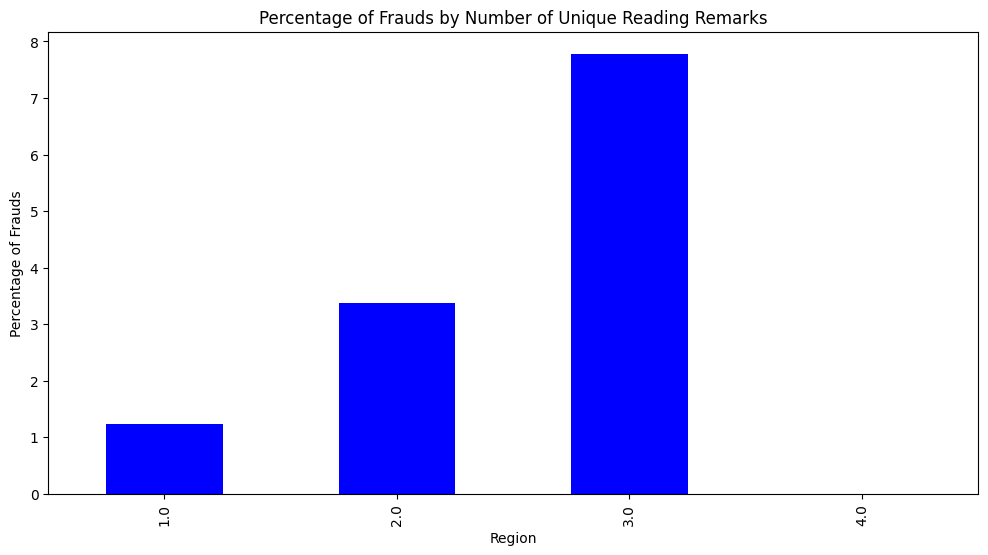

In [ ]:
# Calculate the percentage of frauds by reading_remarque_uniqueness
fraud_pct_reading_remarque = data.groupby("unique_reading_remark_count")["target"].mean() * 100

# Create a bar chart using Matplotlib
fig, ax = plt.subplots(figsize=(12, 6))
fraud_pct_reading_remarque.plot(kind="bar", ax=ax, color="blue")
ax.set_xlabel("Region")
ax.set_ylabel("Percentage of Frauds")
ax.set_title("Percentage of Frauds by Number of Unique Reading Remarks")
plt.show()

From the graph, those who have a consistent `reading_remark` status have a significantly lower rate of fraud with slightly over 1% fraud rate. In contrast, those who have a `unique_reading_remark_count` of 3 has a much higher fraud rate of almost 8%. This suggests that `unique_reading_remark_count` is a potentially significant feature in predicting fraud.

However, one potential downside of `unique_reading_remark_count` we identified is that it does not capture the amount of changes of state. For example, a client whose `reading_remark` state is '6' for first 5 years and then '7' for next 5 years will have a change in state of 1 time. Comparing it with another client whose `reading_remark` state is always changing between '6' and '7' in each invoices (6,7,6,7,...) will have a higher change in state. In both cases, their `unique_reading_remark_count` is 2 but we suspect that a fraudster would usually have a higher change in state. From a fraud-detection perspective, this is suspicious because counters involved in fraud are often tampered with repeatedly, leading to irregular or abnormal readings. Hence, we decide to create a new feature `reading_remark_changed` to help capture this new trend.

In [ ]:
# adding reading_remark changed indicator everytime an invoice encountered a change
elec["reading_remark_changed"] = (
    (elec.groupby("client_id")["reading_remark"].shift() != elec["reading_remark"])
    .fillna(False)
    .astype(int)
)

# create reading remark changes for number of times a client's reading remark has been changed
remark_changes_per_client = (
    elec.groupby("client_id")["reading_remark_changed"]
        .sum()
        .pipe(
            lambda s: pd.cut(
                s,
                bins=[-1, 8, float('inf')],
                labels=[1, 2]
            ).astype(int)
        )
        .rename("remark_changes")
)

# merge into data
data = data.merge(remark_changes_per_client, on="client_id", how="left")

data

,disrict,client_id,client_catg,region,creation_date,target,multiple_counter,consumption_mean,consumption_std,consumption_min,days_since_last_mean,days_since_last_std,days_since_last_max,avg_daily_consumption_mean,avg_daily_consumption_std,avg_daily_consumption_max,unique_reading_remark_count,remark_changes
0,60,train_Client_0,11,101,1994-12-31,0.0,False,362.971429,341.553930,38.0,144.147059,87.601070,508.0,3.568206,5.502266,30.755556,3.0,2.0
1,69,train_Client_1,11,107,2002-05-29,0.0,False,557.540541,197.935960,190.0,136.472222,92.492312,372.0,10.717684,23.122765,117.250000,3.0,2.0
2,62,train_Client_10,11,301,1986-03-13,0.0,False,836.500000,646.808386,188.0,289.470588,250.701794,738.0,4.309229,2.377439,9.400000,3.0,1.0
3,69,train_Client_100,11,105,1996-07-11,0.0,False,1.200000,3.607011,0.0,140.210526,95.569974,442.0,0.009884,0.029847,0.121951,2.0,1.0
4,62,train_Client_1000,11,303,2014-10-14,0.0,False,922.642857,633.485669,124.0,121.923077,80.057752,301.0,50.407931,106.453032,310.750000,2.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
135488,62,train_Client_99995,11,304,2004-07-26,0.0,False,0.000000,0.000000,0.0,141.638889,46.615235,250.0,0.000000,0.000000,0.000000,1.0,1.0
135489,63,train_Client_99996,11,311,2012-10-25,0.0,False,311.250000,226.889464,3.0,121.421053,45.829777,231.0,4.617709,7.557098,29.583333,1.0,1.0
135490,63,train_Client_99997,11,311,2011-11-22,0.0,False,405.000000,164.270683,280.0,134.333333,99.681158,395.0,15.447998,32.593951,128.666667,1.0,1.0
135491,60,train_Client_99998,11,101,1993-12-22,0.0,False,370.500000,232.638131,206.0,122.000000,NaN,122.0,1.688525,NaN,1.688525,2.0,1.0


In this case, those who have 8 or less changes in their `reading_remark` status will have a  `remark_changes` of 1 while those who have more than 8 changes in their `reading_remark` status will have a `remark_changes` of 2.

We decided on 8 as the cutoff after testing different cutoff values. We discovered that the cutoff of 8 resulted in the most significant difference between the fraud percentages while still keeping the total counts of these 2 groups signifiantly large.

In [ ]:
data['remark_changes'].value_counts()

,count
remark_changes,
1.0,85435
2.0,49361


It looks like 85435 clients have a less than 8 changes in their `reading_remark` status and 49361 clients have more than 8 changes in their `reading_remark` status.

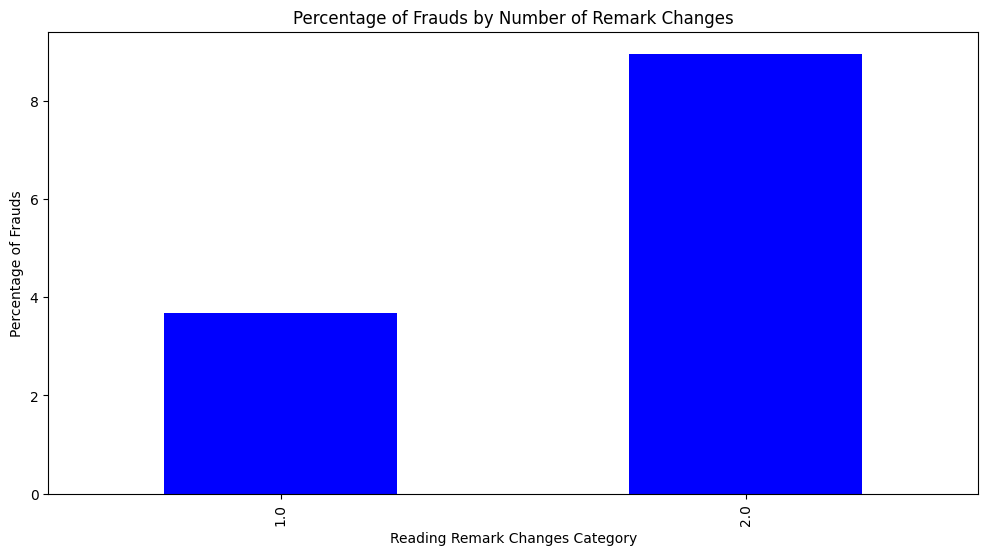

In [ ]:
# Calculate the percentage of frauds by remark_changes
fraud_pct_remark_changes = data.groupby("remark_changes")["target"].mean() * 100

# Create a bar chart using Matplotlib
fig, ax = plt.subplots(figsize=(12, 6))
fraud_pct_remark_changes.plot(kind="bar", ax=ax, color="blue")
ax.set_xlabel("Reading Remark Changes Category")
ax.set_ylabel("Percentage of Frauds")
ax.set_title("Percentage of Frauds by Number of Remark Changes")
plt.show()

From the plot, those who have more than 8 changes in their `reading_remark` status has around 9% of fraud rate, which is significantly higher than those clients whose `remark_changes` of 1.

## Feature Engineering

For feature engineering, one thing we did not take into account is that it is possible for a `region` to appear in multiple `district`. As an analogy, there can be a block 272 in Yishun and another block 272 in Tampines. When combined under the feature `region_272`, it may erronously thought both blocks belong to the same group, which is incorrect. Hence, one feature we created is `area`, which combines both district and area so this potential issue would be addressed.

The creation of `area` will not cause a huge increase in the number of features as most `region`s are only found in one `district`, so curse of dimensionality is not a huge issue.

In [ ]:
data['area'] = data['disrict'].astype(str) + '_' + data['region'].astype(str)

We will remove `region` as it is redundant now we have an `area` feature.

In [ ]:
data.drop(columns=['region'], inplace=True) # remove region

In [ ]:
data

,disrict,client_id,client_catg,creation_date,target,multiple_counter,consumption_mean,consumption_std,consumption_min,days_since_last_mean,days_since_last_std,days_since_last_max,avg_daily_consumption_mean,avg_daily_consumption_std,avg_daily_consumption_max,unique_reading_remark_count,remark_changes,area
0,60,train_Client_0,11,1994-12-31,0.0,False,362.971429,341.553930,38.0,144.147059,87.601070,508.0,3.568206,5.502266,30.755556,3.0,2.0,60_101
1,69,train_Client_1,11,2002-05-29,0.0,False,557.540541,197.935960,190.0,136.472222,92.492312,372.0,10.717684,23.122765,117.250000,3.0,2.0,69_107
2,62,train_Client_10,11,1986-03-13,0.0,False,836.500000,646.808386,188.0,289.470588,250.701794,738.0,4.309229,2.377439,9.400000,3.0,1.0,62_301
3,69,train_Client_100,11,1996-07-11,0.0,False,1.200000,3.607011,0.0,140.210526,95.569974,442.0,0.009884,0.029847,0.121951,2.0,1.0,69_105
4,62,train_Client_1000,11,2014-10-14,0.0,False,922.642857,633.485669,124.0,121.923077,80.057752,301.0,50.407931,106.453032,310.750000,2.0,1.0,62_303
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
135488,62,train_Client_99995,11,2004-07-26,0.0,False,0.000000,0.000000,0.0,141.638889,46.615235,250.0,0.000000,0.000000,0.000000,1.0,1.0,62_304
135489,63,train_Client_99996,11,2012-10-25,0.0,False,311.250000,226.889464,3.0,121.421053,45.829777,231.0,4.617709,7.557098,29.583333,1.0,1.0,63_311
135490,63,train_Client_99997,11,2011-11-22,0.0,False,405.000000,164.270683,280.0,134.333333,99.681158,395.0,15.447998,32.593951,128.666667,1.0,1.0,63_311
135491,60,train_Client_99998,11,1993-12-22,0.0,False,370.500000,232.638131,206.0,122.000000,NaN,122.0,1.688525,NaN,1.688525,2.0,1.0,60_101


Count the number of `area`s.

In [ ]:
data['area'].value_counts()

,count
area,
60_101,31920
69_104,12865
63_311,12406
69_107,9998
62_301,9544
69_103,8964
63_306,6044
62_303,5982
62_310,4851


It is noted that there are 11 clients who live in `area` 62_308 (meaning in `district` 62 and `region` 308), 2 in `area` 60_199 and 1 each in `area` 62_399 and `area` 63_305. It is uncertain if these are data entry error but there is not enough information about the clients in these `area`s so we decide to remove them from the `data`.

In [ ]:
remove = ['63_305', '62_399', '60_199', '62_308']
data = data[~data['area'].isin(remove)]

Replot the percentage of fraud by areas (after removing)

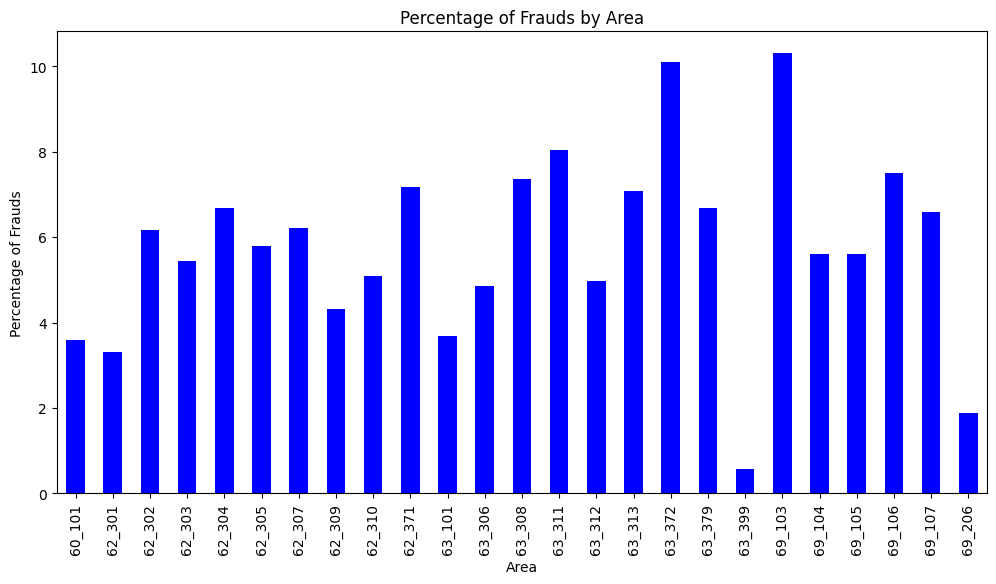

In [ ]:
fraud_pct_area = data.groupby("area")["target"].mean() * 100

# Create a bar chart using Matplotlib
fig, ax = plt.subplots(figsize=(12, 6))
fraud_pct_area.plot(kind="bar", ax=ax, color="blue")
ax.set_xlabel("Area")
ax.set_ylabel("Percentage of Frauds")
ax.set_title("Percentage of Frauds by Area")
plt.show()

The graph is more or less the same as the one in the "Exploratory Data Analysis (Basic)", with `area` 63_372 and 69_103 having a higher fraud rate of approximately 10%.



---

Next, we will perform one hot encoding on features that are categorical.

In [ ]:
data = pd.get_dummies(data, columns=["disrict", "area", "client_catg", "multiple_counter", "unique_reading_remark_count", "remark_changes"], drop_first=True)

Information on the new `data`.

In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 135478 entries, 0 to 135492
Data columns (total 46 columns):
 #   Column                           Non-Null Count   Dtype         
---  ------                           --------------   -----         
 0   client_id                        135478 non-null  object        
 1   creation_date                    135478 non-null  datetime64[ns]
 2   target                           135478 non-null  float64       
 3   consumption_mean                 134783 non-null  float64       
 4   consumption_std                  129771 non-null  float64       
 5   consumption_min                  134783 non-null  float64       
 6   days_since_last_mean             129771 non-null  float64       
 7   days_since_last_std              124284 non-null  float64       
 8   days_since_last_max              129771 non-null  float64       
 9   avg_daily_consumption_mean       129690 non-null  float64       
 10  avg_daily_consumption_std        114801 non-null 

Checking for the number of missing values.

In [ ]:
data.isnull().sum()

,0
client_id,0
creation_date,0
target,0
consumption_mean,695
consumption_std,5707
consumption_min,695
days_since_last_mean,5707
days_since_last_std,11194
days_since_last_max,5707
avg_daily_consumption_mean,5788


For simplicity, we will remove any rows that contains missing data. We have explained why we decided to remove these rows in the previous section (in 'Data Preprocessing')

In [ ]:
data = data.dropna(how='any', axis=0)

Shape of the `data`.

In [ ]:
data.shape

(114801, 46)

Now we have 114801 clients left in our `data`, which is lesser than 114813 clients in `data_baseline`. But that lesser amount of client is almost negligible and the difference in the metrics should have a minimal impact so it is still acceptable.

## Improvement to Baseline Model

**Model Training**

Split data into training and test data

In [ ]:
from sklearn.model_selection import train_test_split

X = data.drop(columns=["client_id", "target", "creation_date"])
y = data["target"]

X_train, X_test, y_train, y_test = train_test_split(X, y, stratify=y, test_size=0.2, random_state=42)

### Logistic Regression

Training our logistic regression model with improved training data.

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, roc_auc_score

logreg = LogisticRegression(class_weight='balanced', max_iter=1000, solver='lbfgs')
logreg.fit(X_train, y_train)

y_pred_log = logreg.predict(X_test)
y_prob_log = logreg.predict_proba(X_test)[:, 1]

print(classification_report(y_test, y_pred_log))
print("AUC:", roc_auc_score(y_test, y_prob_log))

              precision    recall  f1-score   support

         0.0       0.98      0.82      0.89     21712
         1.0       0.18      0.66      0.28      1249

    accuracy                           0.81     22961
   macro avg       0.58      0.74      0.59     22961
weighted avg       0.93      0.81      0.86     22961

AUC: 0.8050136498292222


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Show the confusion matrix of logistic regression.

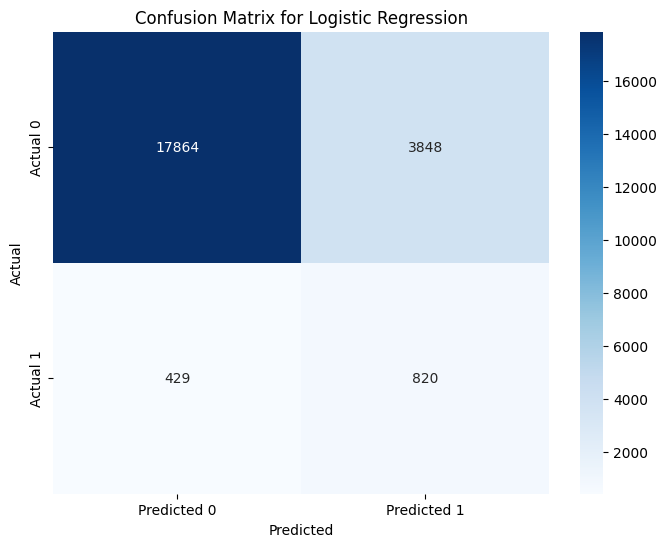

In [ ]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred_log)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=['Predicted 0', 'Predicted 1'],
            yticklabels=['Actual 0', 'Actual 1'])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix for Logistic Regression")
plt.show()

Evaluation metrics on logistic regression.

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score

accuracy = accuracy_score(y_test, y_pred_log)
precision = precision_score(y_test, y_pred_log)
recall = recall_score(y_test, y_pred_log)

print(f"Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")

Accuracy: 0.8137
Precision: 0.1757
Recall: 0.6565


Calculating the PR AUC of logistic regression.

In [ ]:
from sklearn.metrics import precision_recall_curve, auc

precision, recall, thresholds = precision_recall_curve(y_test, y_prob_log)

auc_score = auc(recall, precision)
print('Logistic PR AUC: %.3f' % auc_score)

Logistic PR AUC: 0.192


Displaying the PR Curve for logistic regression.

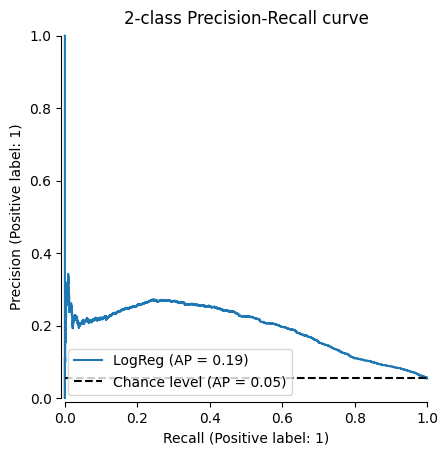

In [ ]:
from sklearn.metrics import PrecisionRecallDisplay

display = PrecisionRecallDisplay.from_predictions(
    y_test, y_prob_log, name="LogReg", plot_chance_level=True, despine=True
)
_ = display.ax_.set_title("2-class Precision-Recall curve")

In [ ]:
import pandas as pd
feature_importance = pd.DataFrame({
    'feature': X.columns,
    'coef': logreg.coef_[0]
}).sort_values(by='coef', ascending=False)

Checking for feature importance.

In [ ]:
feature_importance

,feature,coef
38,multiple_counter_True,2.692022
30,area_69_103,0.935050
11,disrict_69,0.863295
37,client_catg_51,0.429331
42,remark_changes_2.0,0.389817
40,unique_reading_remark_count_3.0,0.364533
15,area_62_304,0.356711
9,disrict_62,0.300713
10,disrict_63,0.270850
34,area_69_107,0.220187


The most significant feature in the feature_importance is `multiple_counter_True`, with a coefficient of 2.69, which is much higher the second most important feature `area_69_103` that has a coefficient of 0.935. As seen in EDA (in depth), a person who has multiple counter have a 18% fraud rate as compared to those who have single counter - whose fraud rate is around 2.5%. This makes sense for multiple_counter to be the most significant features among the variables.

Other feature that have high positive coefficients are `area_69_103`, `disrict_69` and `client_catg_51`, in which clients in these categories have a really high fraud rate as shown in the respective EDA graph. Furthermore, people from region 103, which has the highest fraud rate among all the region, is in district 69, the highest fraud rate among all the districts. This indicates that the high fraud rate in district 69 is partly due to the people living in region 103.
Other features that have relatively high positive coefficients are `remark_changes_2.0` and `unique_reading_remark_count_3.0`, which are also consistent with their respective EDA graphs.



---



Evaluation metrics for logistic regression:

Accuracy | Precision | Recall | ROC AUC | PR AUC
-------- | -------- | -------- | -------- | --------
0.8137| 0.1757 | 0.6565 | 0.8050 | 0.192

Evaluation metrics for logistic regression (from previous data):

Accuracy | Precision | Recall | ROC AUC | PR AUC
-------- | -------- | -------- | -------- | --------
0.6655 | 0.0927 | 0.5861 | 0.6759 | 0.104

Compared to the first baseline model, this model with the improved `data` already have a better accuracy, precision and recall and a better ROC AUC and PR AUC. In particular, the ROC AUC and PR AUC have significantly improved from 0.104 to 0.192 for PR AUC. As our initial baseline model is underfitting, adding more informative features into our `data` such as 'multiple_counter' helps the model to fit more closer to the training data, thereby decreasing bias and make the model less prone to underfitting.

**HYPERPARAMETER TUNING for logistic regression**

'C' is the inverse of regularization strength (L2 by default). A high value of C will mean weaker regularization, so model fits training data more closely but risk overfitting. A low value of C will mean stronger regularization, so model will be more simpler with smaller coefficients but risk underfitting.

In [ ]:
from sklearn.model_selection import GridSearchCV

param_grid = {'C': [0.01, 0.1, 1, 10]}
grid = GridSearchCV(
    LogisticRegression(class_weight='balanced', solver='lbfgs', max_iter=1000),
    param_grid,
    scoring='average_precision',
    cv=5,
    n_jobs=-1
)
grid.fit(X_train, y_train)
print("Best C:", grid.best_params_)

Best C: {'C': 1}


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


From the hyperparameter tuning, the optimal value of C is 1, which is the default value (from the scikit-learn user guide). This means that the previous model `logreg` is already at tuned to the best.

In [ ]:
print(grid.best_score_)

0.19738509363487725


Therefore, the best CV validation of PR AUC is around 0.197.

In [ ]:
model = LogisticRegression(
    class_weight='balanced',
    max_iter=1000,
    solver='lbfgs',
    C = 1 #need to check if this is correct...
)

model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print(classification_report(y_test, y_pred))
print("AUC:", roc_auc_score(y_test, model.predict_proba(X_test)[:, 1]))

              precision    recall  f1-score   support

         0.0       0.98      0.82      0.89     21712
         1.0       0.18      0.66      0.28      1249

    accuracy                           0.81     22961
   macro avg       0.58      0.74      0.59     22961
weighted avg       0.93      0.81      0.86     22961

AUC: 0.8050136498292222


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [ ]:
y_prob = model.predict_proba(X_test)[:, 1]
y_pred = np.where(y_prob > 0.5, 1, 0)

Show the confusion matrix of logistic regression (tuned).

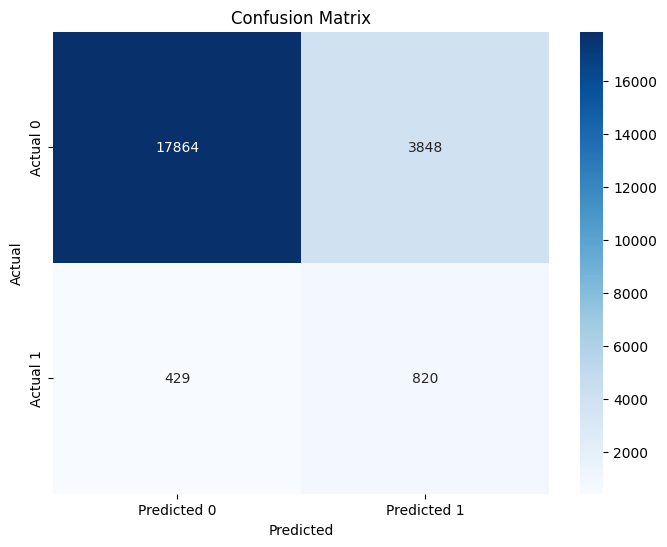

In [ ]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=['Predicted 0', 'Predicted 1'],
            yticklabels=['Actual 0', 'Actual 1'])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

Evaluation metrics on logistic regression (tuned).

In [ ]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)

print(f"Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")

Accuracy: 0.8137
Precision: 0.1757
Recall: 0.6565


Calculating the PR AUC of logistic regression (tuned).

In [ ]:
precision, recall, thresholds = precision_recall_curve(y_test, y_prob)

auc_score = auc(recall, precision)
print('Logistic PR AUC: %.3f' % auc_score)

Logistic PR AUC: 0.192


Displaying the PR Curve for logistic regression (tuned).

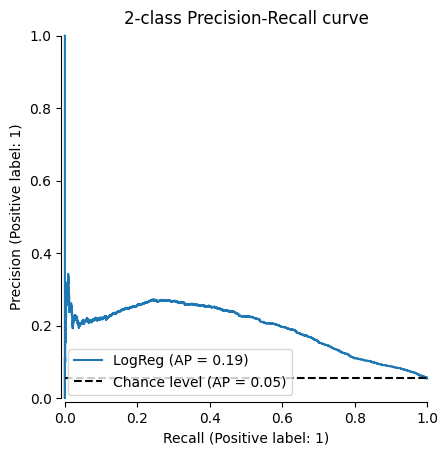

In [ ]:
display = PrecisionRecallDisplay.from_predictions(
    y_test, y_prob, name="LogReg", plot_chance_level=True, despine=True
)
_ = display.ax_.set_title("2-class Precision-Recall curve")

## Advanced Model Training

So far, we have been using parametric models (logistic regression). Next, we will be moving on to non-parametric models, mainly tree-based models such as random forest, XGBoost and LightGBM. They are known to have a better predictive power than logistic regression [An Introduction to Statistical Learning: with Applications in Python - Chapter 8: Tree-Based Methods].

### Random Forest

In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(class_weight='balanced', n_estimators=200, random_state=42)
rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_test)
y_prob_rf = rf.predict_proba(X_test)[:, 1]

print(classification_report(y_test, y_pred_rf))
print("AUC:", roc_auc_score(y_test, y_prob_rf))

              precision    recall  f1-score   support

         0.0       0.95      1.00      0.97     21712
         1.0       0.54      0.03      0.06      1249

    accuracy                           0.95     22961
   macro avg       0.74      0.52      0.52     22961
weighted avg       0.93      0.95      0.92     22961

AUC: 0.8094551912716613


Show the confusion matrix of random forest.

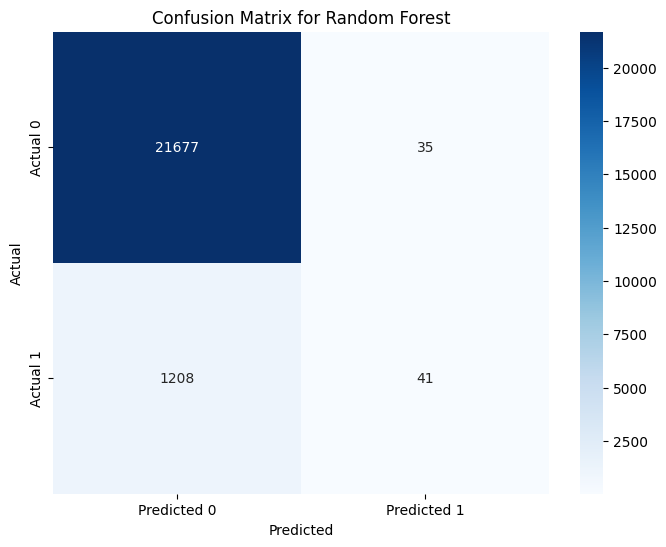

In [ ]:
cm = confusion_matrix(y_test, y_pred_rf)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=['Predicted 0', 'Predicted 1'],
            yticklabels=['Actual 0', 'Actual 1'])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix for Random Forest")
plt.show()

Evaluation metrics on random forest.

In [ ]:
accuracy = accuracy_score(y_test, y_pred_rf)
precision = precision_score(y_test, y_pred_rf)
recall = recall_score(y_test, y_pred_rf)

print(f"Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")

Accuracy: 0.9459
Precision: 0.5395
Recall: 0.0328


Calculating the PR AUC of random forest.

In [ ]:
precision, recall, thresholds = precision_recall_curve(y_test, y_prob_rf)

auc_score = auc(recall, precision)
print('Logistic PR AUC: %.3f' % auc_score)

Logistic PR AUC: 0.242


Displaying the PR Curve for random forest.

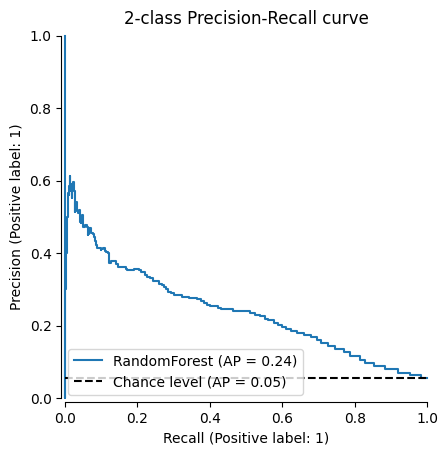

In [ ]:
display = PrecisionRecallDisplay.from_predictions(
    y_test, y_prob_rf, name="RandomForest", plot_chance_level=True, despine=True
)
_ = display.ax_.set_title("2-class Precision-Recall curve")

Evaluation metrics for random forest:

Accuracy | Precision | Recall | ROC AUC | PR AUC
-------- | -------- | -------- | -------- | --------
0.9459 | 0.5395 | 0.0328 | 0.8095 | 0.242

**HYPERPARAMETER TUNING** for random forest

* 'n_estimators' is the number of trees in the forest. Having more trees can help reduce variance and improve stability but it becomes computationally more expensive.
* 'max_depth' is the maximum depth allowed for each decision tree. This hyperparameter controls complexity; a shallow trees is prone to underfit while very deep trees tends to overfit.
* 'min_samples_split' is the minimum number of samples required to split a node. Having larger min_sample_split values reduce overfitting by preventing overly specific splits.
* 'min_samples_leaf' is the minimum samples required in a leaf node.
Having larger min_sample_leaf will mean larger leaf nodes, which makes the model less likely to overfit.
* 'criterion' is the metric used to evaluate split quality (e.g., "gini", "entropy"). Different criteria yield different splitting behavior; it can affect accuracy and training time.




---


⚠️***WARNING!: Code takes more than 100 minutes to execute!!!***

In [ ]:
from sklearn.model_selection import RandomizedSearchCV

param_grid = {
    'n_estimators': [200, 500, 800],
    'max_depth': [None, 10, 20, 40],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4, 8],
    'criterion': ['gini', 'entropy', 'log_loss']
}

rf = RandomForestClassifier(class_weight='balanced', random_state=42)
grid = RandomizedSearchCV(
    rf,
    param_grid,
    scoring='average_precision',
    cv=5,
    n_jobs=-1
)
grid.fit(X_train, y_train)
print(grid.best_params_)

/usr/local/lib/python3.12/dist-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


{'n_estimators': 500, 'min_samples_split': 10, 'min_samples_leaf': 8, 'max_depth': None, 'criterion': 'log_loss'}


In [ ]:
print(f"Best PR AUC score: {grid.best_score_:.4f}")

Best PR AUC score: 0.2719


Therefore, the best CV validation of PR AUC is around 0.272.

In [ ]:
rf = RandomForestClassifier(
    class_weight='balanced',
    n_estimators = 500,
    min_samples_split = 10,
    min_samples_leaf = 8,
    random_state=42,
    max_depth = None,
    criterion = 'log_loss'
)
rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_test)
y_prob_rf = rf.predict_proba(X_test)[:, 1]

print(classification_report(y_test, y_pred_rf))
print("AUC:", roc_auc_score(y_test, y_prob_rf))

              precision    recall  f1-score   support

         0.0       0.97      0.91      0.94     21712
         1.0       0.26      0.51      0.34      1249

    accuracy                           0.89     22961
   macro avg       0.61      0.71      0.64     22961
weighted avg       0.93      0.89      0.91     22961

AUC: 0.825730186212345


Show the confusion matrix of random forest (tuned).

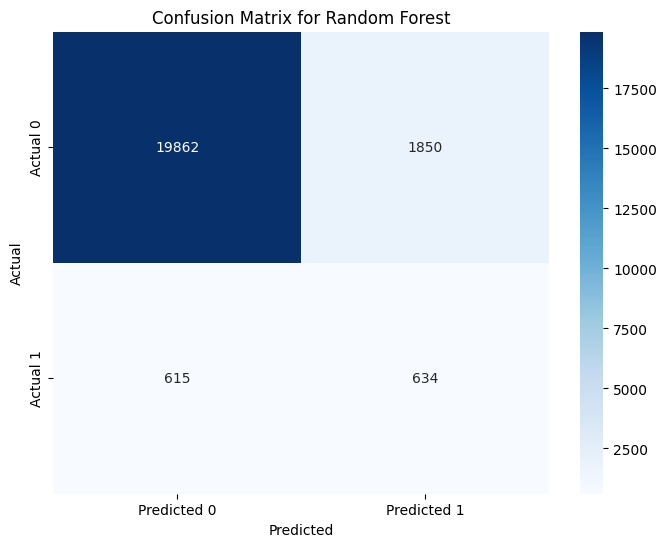

In [ ]:
cm = confusion_matrix(y_test, y_pred_rf)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=['Predicted 0', 'Predicted 1'],
            yticklabels=['Actual 0', 'Actual 1'])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix for Random Forest")
plt.show()

Evaluation metrics on random forest (tuned).

In [ ]:
accuracy = accuracy_score(y_test, y_pred_rf)
precision = precision_score(y_test, y_pred_rf)
recall = recall_score(y_test, y_pred_rf)

print(f"Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")

Accuracy: 0.8926
Precision: 0.2552
Recall: 0.5076


Calculating the PR AUC of random forest (tuned).

In [ ]:
precision, recall, thresholds = precision_recall_curve(y_test, y_prob_rf)

auc_score = auc(recall, precision)
print('Logistic PR AUC: %.3f' % auc_score)

Logistic PR AUC: 0.260


Displaying the PR Curve for random forest (tuned).

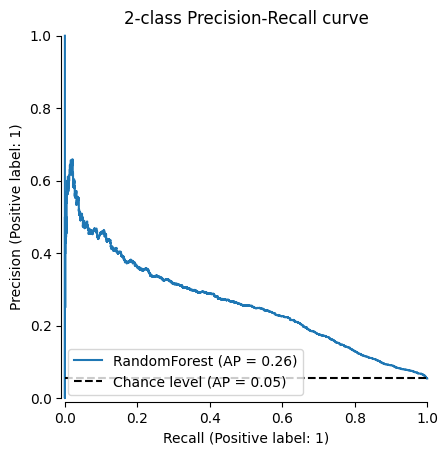

In [ ]:
display = PrecisionRecallDisplay.from_predictions(
    y_test, y_prob_rf, name="RandomForest", plot_chance_level=True, despine=True
)
_ = display.ax_.set_title("2-class Precision-Recall curve")

In summary, the evaluation metrics for random forest is as follows:

Model | Accuracy | Precision | Recall | ROC AUC | PR AUC
-------- | -------- | -------- | -------- | -------- | --------
Not tuned | 0.9459 | 0.5395 | 0.0328 | 0.8095 | 0.242
Tuned | 0.8926| 0.2552 | 0.5076 | 0.8257 | 0.260


### XGBoost

In [ ]:
from xgboost import XGBClassifier

scale = len(y_train[y_train==0]) / len(y_train[y_train==1])
xgb = XGBClassifier(scale_pos_weight=scale, eval_metric='auc', random_state=42)
xgb.fit(X_train, y_train)

y_pred_xgb = xgb.predict(X_test)
y_prob_xgb = xgb.predict_proba(X_test)[:, 1]

print(classification_report(y_test, y_pred_xgb))
print("AUC:", roc_auc_score(y_test, y_prob_xgb))

              precision    recall  f1-score   support

         0.0       0.97      0.85      0.91     21712
         1.0       0.18      0.60      0.28      1249

    accuracy                           0.83     22961
   macro avg       0.58      0.72      0.59     22961
weighted avg       0.93      0.83      0.87     22961

AUC: 0.8035231243211223


Show the confusion matrix of XGBoost.

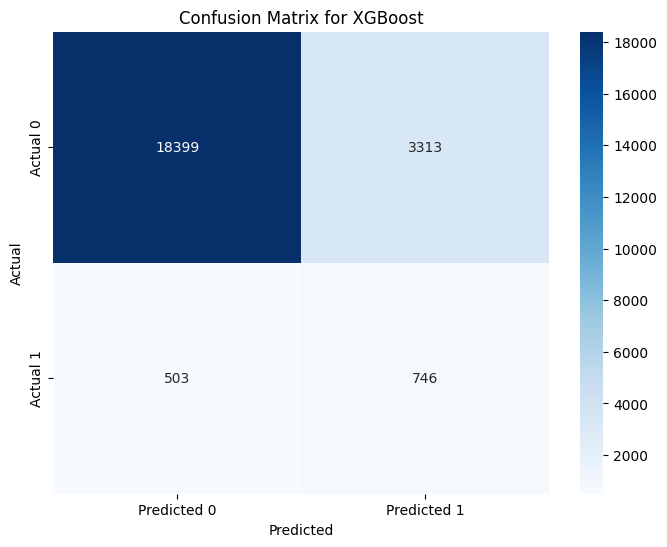

In [ ]:
cm = confusion_matrix(y_test, y_pred_xgb)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=['Predicted 0', 'Predicted 1'],
            yticklabels=['Actual 0', 'Actual 1'])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix for XGBoost")
plt.show()

Evaluation metrics on XGBoost.

In [ ]:
accuracy = accuracy_score(y_test, y_pred_xgb)
precision = precision_score(y_test, y_pred_xgb)
recall = recall_score(y_test, y_pred_xgb)

print(f"Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")

Accuracy: 0.8338
Precision: 0.1838
Recall: 0.5973


Calculating the PR AUC of XGBoost.

In [ ]:
precision, recall, thresholds = precision_recall_curve(y_test, y_prob_xgb)

auc_score = auc(recall, precision)
print('Logistic PR AUC: %.3f' % auc_score)

Logistic PR AUC: 0.236


Displaying the PR Curve for XGBoost.

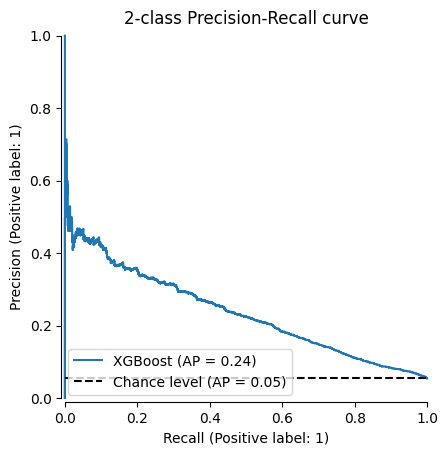

In [ ]:
display = PrecisionRecallDisplay.from_predictions(
    y_test, y_prob_xgb, name="XGBoost", plot_chance_level=True, despine=True
)
_ = display.ax_.set_title("2-class Precision-Recall curve")

Evaluation metrics for XGBoost:

Accuracy | Precision | Recall | ROC AUC | PR AUC
-------- | -------- | -------- | -------- | --------
0.8338 | 0.1838 | 0.5973 | 0.8035 | 0.236

**HYPERPARAMETER TUNING** for XGBoost

* 'learning_rate' (eta) is the shrinking step size for each boosting update. A lower rates improve generalization but require more trees; a higher rate may cause overfitting.
* 'max_depth' is the maximum depth of each tree. Deeper trees allow modeling complex interactions but increase overfitting risk.
* 'subsample' is the fraction of rows sampled per tree.
It reduces variance and overfitting by injecting randomness.
* 'colsample_bytree' is the fraction of features sampled per tree. It prevents trees from relying too heavily on certain features, thus reduces overfitting.
* reg_alpha (L1 regularization) is the L1 penalty on leaf weights. It encourages sparsity in the model and it is helpful for high-dimensional data.
* scale_pos_weight is the weighting factor for positive class in imbalanced classification. It helps to adjust the loss function so the model pays more attention to minority classes (fraud).

In [ ]:
from sklearn.model_selection import RandomizedSearchCV

param_grid = {
    'learning_rate': [0.01, 0.05, 0.1],
    'max_depth': [3, 5, 7],
    'subsample': [0.6, 0.8, 1.0],
    'colsample_bytree': [0.6, 0.8, 1.0],
    'reg_alpha': [0, 0.001, 0.01, 0.1, 0.5],
    'scale_pos_weight': np.linspace(scale - 5, scale + 5, 10).tolist() # Centered around previously calculated value
}

xgb = XGBClassifier(
    eval_metric='logloss',
    random_state=42,
    tree_method='hist'  # faster for large dataset
)

search = RandomizedSearchCV(
    estimator=xgb,
    param_distributions=param_grid,
    n_iter=50,
    scoring='average_precision',
    cv=3,
    verbose=1,
    random_state=42,
    n_jobs=-1
)

search.fit(X_train, y_train)
print(search.best_params_)

Fitting 3 folds for each of 50 candidates, totalling 150 fits
{'subsample': 0.8, 'scale_pos_weight': 13.493817276043057, 'reg_alpha': 0, 'max_depth': 5, 'learning_rate': 0.05, 'colsample_bytree': 0.8}


In [ ]:
print(f"Best PR AUC score: {search.best_score_:.4f}")

Best PR AUC score: 0.2741


Therefore, the best CV validation of PR AUC is around 0.274.

In [ ]:
xgb = XGBClassifier(eval_metric='logloss', tree_method = 'hist', random_state=42,
                    scale_pos_weight=13.493817276043057,
                    subsample=0.8,
                    reg_alpha=0,
                    max_depth=5,
                    learning_rate=0.05,
                    colsample_bytree=0.8
                    )
xgb.fit(X_train, y_train)

y_pred_xgb = xgb.predict(X_test)
y_prob_xgb = xgb.predict_proba(X_test)[:, 1]

print(classification_report(y_test, y_pred_xgb))
print("AUC:", roc_auc_score(y_test, y_prob_xgb))

              precision    recall  f1-score   support

         0.0       0.98      0.84      0.90     21712
         1.0       0.19      0.66      0.30      1249

    accuracy                           0.83     22961
   macro avg       0.59      0.75      0.60     22961
weighted avg       0.93      0.83      0.87     22961

AUC: 0.8268614338781268


Show the confusion matrix of XGBoost (tuned).

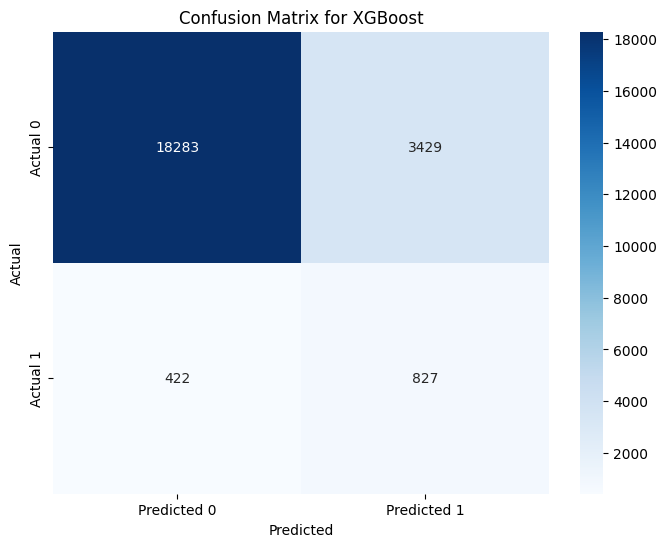

In [ ]:
cm = confusion_matrix(y_test, y_pred_xgb)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=['Predicted 0', 'Predicted 1'],
            yticklabels=['Actual 0', 'Actual 1'])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix for XGBoost")
plt.show()

Evaluation metrics on XGBoost (tuned).

In [ ]:
accuracy = accuracy_score(y_test, y_pred_xgb)
precision = precision_score(y_test, y_pred_xgb)
recall = recall_score(y_test, y_pred_xgb)

print(f"Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")

Accuracy: 0.8323
Precision: 0.1943
Recall: 0.6621


Calculating the PR AUC of XGBoost (tuned).

In [ ]:
precision, recall, thresholds = precision_recall_curve(y_test, y_prob_xgb)

auc_score = auc(recall, precision)
print('Logistic PR AUC: %.3f' % auc_score)

Logistic PR AUC: 0.262


Displaying the PR Curve for XGBoost (tuned).

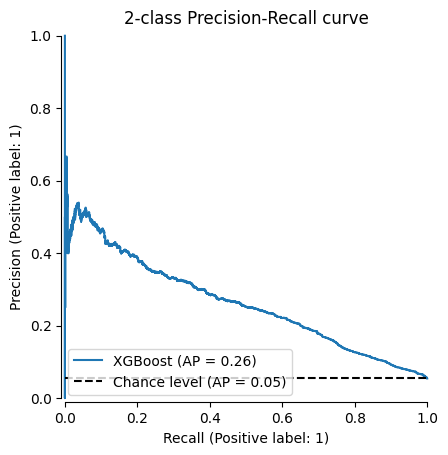

In [ ]:
display = PrecisionRecallDisplay.from_predictions(
    y_test, y_prob_xgb, name="XGBoost", plot_chance_level=True, despine=True
)
_ = display.ax_.set_title("2-class Precision-Recall curve")

In summary, the evaluation metrics for XGBoost is as follows:

Model | Accuracy | Precision | Recall | ROC AUC | PR AUC
-------- | -------- | -------- | -------- | -------- | --------
Not tuned | 0.8338 | 0.1838 | 0.5973 | 0.8035 | 0.236
Tuned | 0.8323 | 0.1943 | 0.6621 | 0.8269 | 0.262

We shall use SHAP (SHapley Additive exPlanations) as to explain the model.

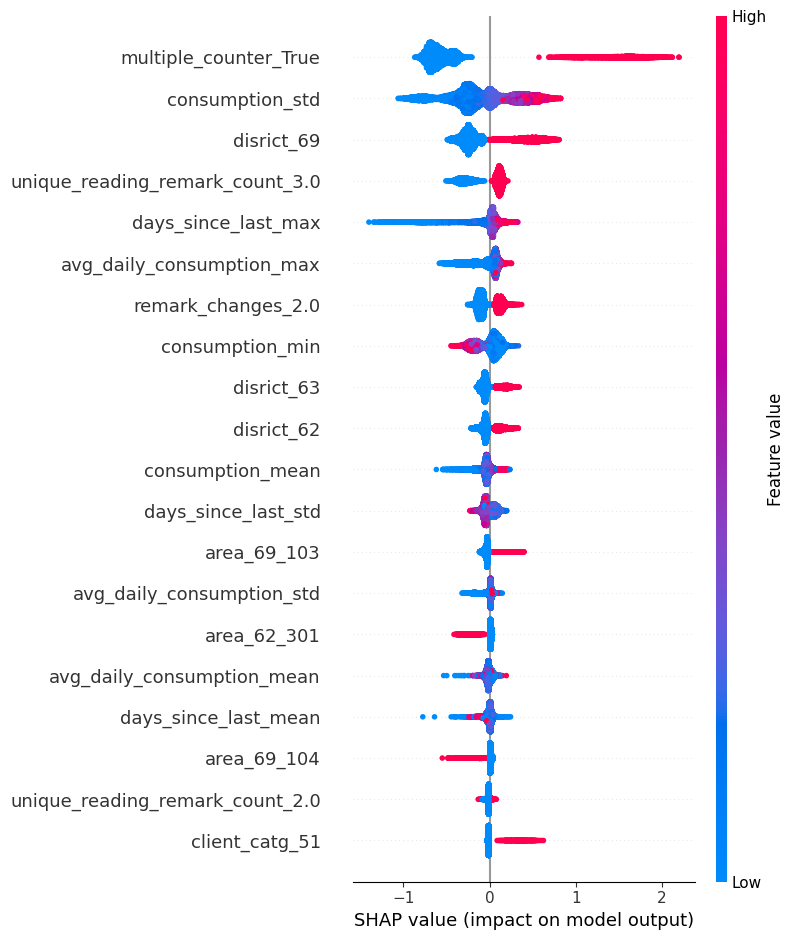

In [ ]:
import shap

explainer = shap.TreeExplainer(xgb)
shap_values = explainer.shap_values(X_test)

shap.summary_plot(shap_values, X_test)

shap.force_plot(
    explainer.expected_value,
    shap_values[0, :],
    X_test.iloc[0, :]
)

From the SHAP summary plot, the feature that has the most impact are the those at the top, with `multiple_counter_True` being the most impactful, followed by `consumption_std`, `disrict_69` and so on. For `multiple_counter_True`, we can observe that when a client has multiple counters, the probability of them committing fraud strongly increase, meaning that they are more likely to commit fraud. However, the spread of the red value would indicate the high variance - sometimes having `multiple_counter_True` as True may strongly pushes the prediction up; sometimes, it does not. This can be due to the fact that there are noise in the data. Just having multiple counter does not mean it is guaranteed that client committed fraud, hence the variance would be large.

Another important feature is `consumption_std`, where high variability (in red) pushes the predictions up while low variability (in blue) pushes them down or remain neutral. This implies that unstable consumption patterns are a strong signal that a client may be committing fraud.

Moreover, the graph suggest that `district` is a more significant factor than `area`, with `district_69` being the third most important feature while `district_62` and `district_63` also appear in the top 10. People from `district_69` do tend to have higher probability of committing fraud, which is supported by EDA. It does indicate that `district` is a stronger geographic pattern than `area`. This results seems shocking but upon further analysis, it does make sense as the multiple `area`s with different rate of frauds become noise that sometimes does not add value to the prediction. Utlimately, `district` does contain sufficient information on fraud rate so it becomes more significant.

### LightGBM

In [ ]:
from lightgbm import LGBMClassifier

lgbm = LGBMClassifier(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=6,
    class_weight="balanced"
)
lgbm.fit(X_train, y_train)

# Evaluate
y_pred_lgbm = lgbm.predict(X_test)
y_prob_lgbm = lgbm.predict_proba(X_test)[:, 1]

print(classification_report(y_test, y_pred_lgbm))
print("AUC:", roc_auc_score(y_test, y_prob_lgbm))

[LightGBM] [Info] Number of positive: 4996, number of negative: 86844
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.022798 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 2361
[LightGBM] [Info] Number of data points in the train set: 91840, number of used features: 42
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=-0.000000
[LightGBM] [Info] Start training from score -0.000000
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain

Show the confusion matrix of LightGBM.

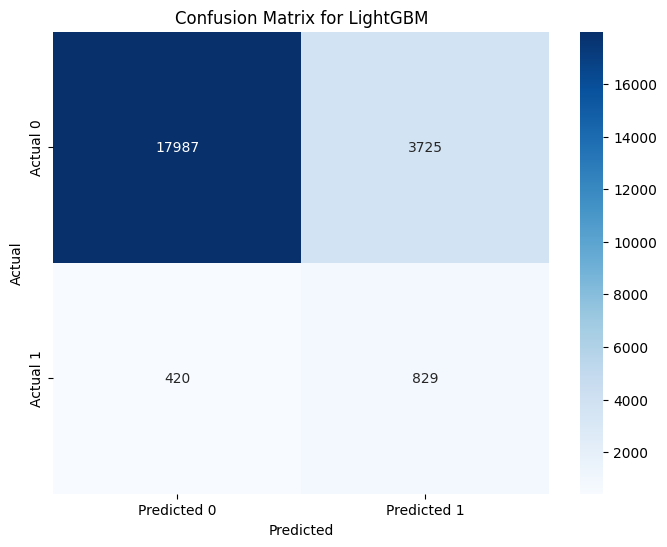

In [ ]:
cm = confusion_matrix(y_test, y_pred_lgbm)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=['Predicted 0', 'Predicted 1'],
            yticklabels=['Actual 0', 'Actual 1'])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix for LightGBM")
plt.show()

Evaluation metrics on LightGBM.

In [ ]:
accuracy = accuracy_score(y_test, y_pred_lgbm)
precision = precision_score(y_test, y_pred_lgbm)
recall = recall_score(y_test, y_pred_lgbm)

print(f"Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")

Accuracy: 0.8195
Precision: 0.1820
Recall: 0.6637


Calculating the PR AUC of LightGBM.

In [ ]:
precision, recall, thresholds = precision_recall_curve(y_test, y_prob_lgbm)

auc_score = auc(recall, precision)
print('Logistic PR AUC: %.3f' % auc_score)

Logistic PR AUC: 0.252


Displaying the PR Curve for LightGBM.

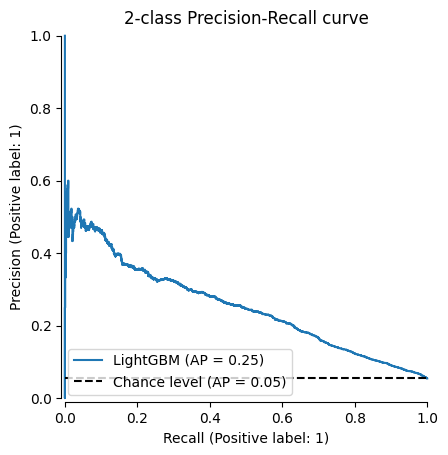

In [ ]:
display = PrecisionRecallDisplay.from_predictions(
    y_test, y_prob_lgbm, name="LightGBM", plot_chance_level=True, despine=True
)
_ = display.ax_.set_title("2-class Precision-Recall curve")

Evaluation metrics for LightGBM:

Accuracy | Precision | Recall | ROC AUC | PR AUC
-------- | -------- | -------- | -------- | --------
0.8195 | 0.1820 | 0.6637 | 0.8193 | 0.252

**HYPERPARAMETER TUNING** for LightGBM

* 'num_leaves' is the maximum number of leaf nodes per tree. This hyperparameter controls model complexity. More leaves capture more patterns but overfit easily and vice versa.
* 'max_depth' is the maximum depth of the tree. Its function is similar to Random Forest/XGBoost. It is often tuned along with num_leaves.
* 'min_split_gain' is the minimum gain required to make a split. It prevents splits that provide little information, which reduces overfitting.
* 'subsample' (bagging_fraction) is the fraction of rows sampled per iteration. Like Random Forest/XGBoost, it helps reduce overfitting through randomness.
* 'subsample_freq' refers to how often (every N iterations) subsampling is performed. It balances stability vs. randomness. It is used with subsample.
* 'colsample_bytree' (feature_fraction) is the fraction of features used per tree. It reduces overfitting and speeds up training.
* 'lambda_l1' is the L1 regularization on leaf weights. It helps with sparsity and prevents overfitting.
* 'lambda_l2' is the L2 regularization on leaf weights.
It smooths leaf weights which helps prevent overfitting and stabilize training.

In [ ]:
param_grid = {
    'num_leaves': [31, 63, 127],
    'max_depth': [-1, 4, 6, 8],
    'min_split_gain': [0, 0.01, 0.1],
    'subsample': [0.6, 0.8, 1.0],
    'subsample_freq': [0, 1, 5],
    'colsample_bytree': [0.6, 0.8, 1.0],
    'lambda_l1': [0, 0.1, 0.5],
    'lambda_l2': [0, 0.1, 0.5]
}

lgbm = LGBMClassifier(
    n_estimators=500,
    learning_rate=0.05,
    random_state=42
)

search = RandomizedSearchCV(
    estimator=lgbm,
    param_distributions=param_grid,
    n_iter=50,
    scoring='average_precision',
    cv=3,
    verbose=1,
    random_state=42,
    n_jobs=-1
)

search.fit(X_train, y_train)
print(search.best_params_)

Fitting 3 folds for each of 50 candidates, totalling 150 fits
[LightGBM] [Warning] lambda_l2 is set=0.5, reg_lambda=0.0 will be ignored. Current value: lambda_l2=0.5
[LightGBM] [Warning] lambda_l1 is set=0.1, reg_alpha=0.0 will be ignored. Current value: lambda_l1=0.1
[LightGBM] [Warning] lambda_l2 is set=0.5, reg_lambda=0.0 will be ignored. Current value: lambda_l2=0.5
[LightGBM] [Warning] lambda_l1 is set=0.1, reg_alpha=0.0 will be ignored. Current value: lambda_l1=0.1
[LightGBM] [Info] Number of positive: 4996, number of negative: 86844
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.020023 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 2361
[LightGBM] [Info] Number of data points in the train set: 91840, number of used features: 42
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.054399 -> initscore=-2.855476
[LightGBM] [Info] Start training from score -2.855476
[LightGBM] [Warning] No further

In [ ]:
print(f"Best PR AUC score: {search.best_score_:.4f}")

Best PR AUC score: 0.2752


Therefore, the best CV validation of PR AUC is around 0.275.

In [ ]:
lgbm = LGBMClassifier(
    n_estimators=500,
    learning_rate=0.05,
    class_weight="balanced",
    subsample_freq=1,
    subsample=0.8,
    num_leaves=127,
    min_split_gain=0,
    max_depth=4,
    lambda_l2=0.5,
    lambda_l1=0.1,
    colsample_bytree=1.0
)

lgbm.fit(X_train, y_train)

# Evaluate
y_pred_lgbm = lgbm.predict(X_test)
y_prob_lgbm = lgbm.predict_proba(X_test)[:, 1]

print(classification_report(y_test, y_pred_lgbm))
print("AUC:", roc_auc_score(y_test, y_prob_lgbm))

[LightGBM] [Warning] lambda_l2 is set=0.5, reg_lambda=0.0 will be ignored. Current value: lambda_l2=0.5
[LightGBM] [Warning] lambda_l1 is set=0.1, reg_alpha=0.0 will be ignored. Current value: lambda_l1=0.1
[LightGBM] [Warning] lambda_l2 is set=0.5, reg_lambda=0.0 will be ignored. Current value: lambda_l2=0.5
[LightGBM] [Warning] lambda_l1 is set=0.1, reg_alpha=0.0 will be ignored. Current value: lambda_l1=0.1
[LightGBM] [Info] Number of positive: 4996, number of negative: 86844
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.020196 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 2361
[LightGBM] [Info] Number of data points in the train set: 91840, number of used features: 42
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=-0.000000
[LightGBM] [Info] Start training from score -0.000000
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warnin

Show the confusion matrix of LightGBM (tuned).

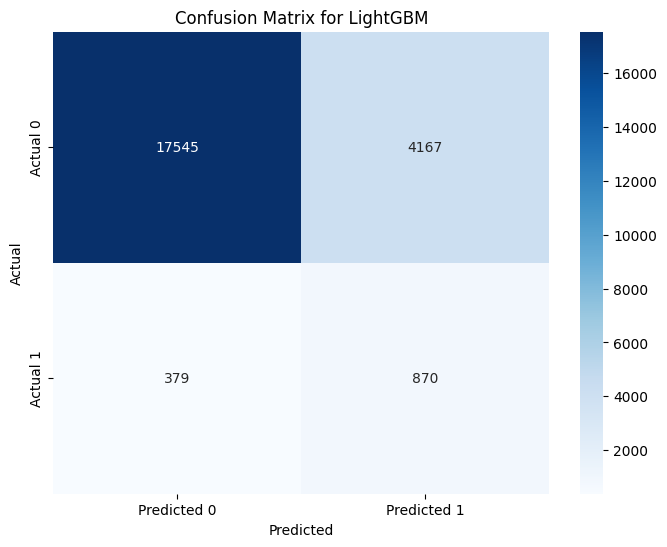

In [ ]:
cm = confusion_matrix(y_test, y_pred_lgbm)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=['Predicted 0', 'Predicted 1'],
            yticklabels=['Actual 0', 'Actual 1'])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix for LightGBM")
plt.show()

Evaluation metrics on LightGBM (tuned).

In [ ]:
accuracy = accuracy_score(y_test, y_pred_lgbm)
precision = precision_score(y_test, y_pred_lgbm)
recall = recall_score(y_test, y_pred_lgbm)

print(f"Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")

Accuracy: 0.8020
Precision: 0.1727
Recall: 0.6966


Calculating the PR AUC of LightGBM (tuned).

In [ ]:
precision, recall, thresholds = precision_recall_curve(y_test, y_prob_lgbm)

auc_score = auc(recall, precision)
print('Logistic PR AUC: %.3f' % auc_score)

Logistic PR AUC: 0.252


Displaying the PR Curve for LightGBM (tuned).

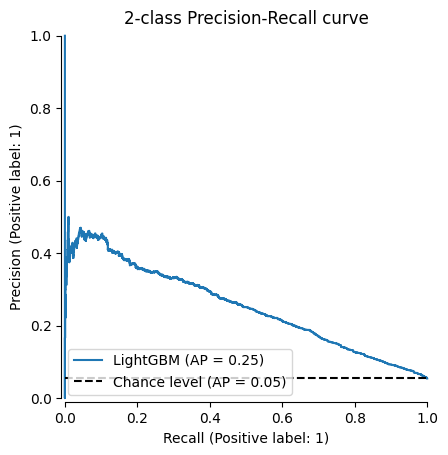

In [ ]:
display = PrecisionRecallDisplay.from_predictions(
    y_test, y_prob_lgbm, name="LightGBM", plot_chance_level=True, despine=True
)
_ = display.ax_.set_title("2-class Precision-Recall curve")

In summary, the evaluation metrics for LightGBM is as follows:

Model | Accuracy | Precision | Recall | ROC AUC | PR AUC
-------- | -------- | -------- | -------- | -------- | --------
Not tuned | 0.8195 | 0.1820 | 0.6637 | 0.8193 | 0.252
Tuned | 0.8020 | 0.1727 | 0.6966 | 0.8248 | 0.252

Again, we will use SHAP to explain the LightGBM.

/usr/local/lib/python3.12/dist-packages/shap/explainers/_tree.py:587: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


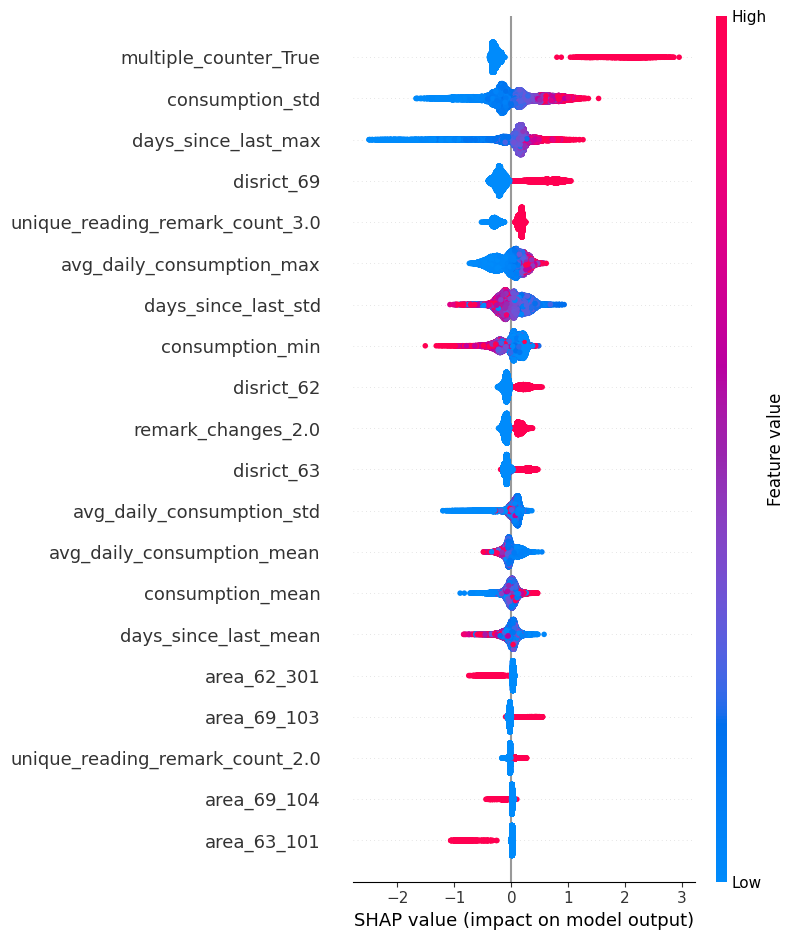

In [ ]:
import shap

explainer = shap.TreeExplainer(lgbm)
shap_values = explainer.shap_values(X_test)

shap.summary_plot(shap_values, X_test)

shap.force_plot(
    explainer.expected_value,
    shap_values[0, :],
    X_test.iloc[0, :]
)

From the SHAP summary plot, the most important feature is `multiple_counter`, in which someone who has multiple counter are much more likely to commit fraud compared to those who does not. Also, similar to XGBoost, the spread of the red values indicates high variance, thus sometimes having a multiple counter strongly pushes the prediction up; sometimes it does not. This means that `multiple_counter_True` is the most significant feature in every model, which makes sense as seen from EDA (in depth), having multiple_counter = True has a fraud rate of 18% versus having multiple_counter = False that has a fraud rate of around 2.5%, which is much more significant than the rest of the features.

The second most important feature is `consumption_std`, the same as in XGBoost. The third most important is `days_since_last_max` instead of `disrict_69` as seen in XGBoost. We understand that if someone commits fraud, there will be a time where the time between invoices is very great - to avoid payment for a particular time period and tampering with the meter so that their electrical consumption will say correspond to a 4 months consumption instead of a 8 months consumption. `days_since_last_max` is able to capture this type of fraud, hence those with relatively high `days_since_last_max` is more likely to be committing fraud. However, we also note that the spread of the blue values is very large - the largest spread in the summary plot. This means that for a person with a small `days_since_last_max` value, sometimes it will strongly push the prediction down; sometimes it will not.

Another insights from the SHAP summary plots of both XGBoost and LightGBM is that `unique_reading_remark` and `reading_changes` are not as significant as we hope for. We theorize that for both of these features, the fraud rates in each of the category are not very significant from each other. Thus, it does not have a huge impact on the model's prediction.

## Results and Evaluation

Here is a summary on our models (after tuning):

MODELS | Accuracy | Precision | Recall | ROC AUC | PR AUC
-------- | -------- | -------- | -------- | -------- | --------
Logistic Regression | 0.8137| 0.1757 | 0.6565 | 0.8050 | 0.192
Random Forest | 0.8926| 0.2552 | 0.5076 | 0.8257 | 0.260
XGBoost | 0.8323 | 0.1943 | 0.6621 | 0.8269 | 0.262
LightGBM | 0.8020 | 0.1727 | 0.6966 | 0.8248 | 0.252

XGBoost has the highest PR AUC among the models.
Since XGBoost is a type of boosting algorithm, which means it builds trees sequentially and focuses on difficult minority samples, hence it is ideal for fraud detection. It can handle sparse or skewed features well (often true for consumption data) and naturally captures nonlinear relationships between usage patterns and fraud, which explains why it perform relatively good.

LightGBM is another boosting algorithm, but our emphasis on recall makes the leaf-wise growth to aggressively optimize recall. However, it is more prone to overfitting minority class noise due to its tree-growing strategy, which explaines why it has the highest recall among the models but this trade-off means that it has a worse precision, causing the model to have output too many false positive.

Random Forest is bagging, which builds many decision trees that are usually uncorrelated with each other. From the table, it has the best precision because it makes more conservative fraud predictions, requiring strong evidence to consider someone to be a fraudster. However, that means random forest would be weaker at capturing rare events, causing it to have a poorer recall. This makes random forest a less appealing model as compared to the other boosting models, perhaps that boosting will improve the performance of an underfitting model more than bagging.

Logistic regression is the only parametric model that we used. As logistic regression is linear, it struggles when fraud patterns are not linearly separable. This is a reason why it has the worst ROC and PR AUC as it is unable to capture the complex patterns in the data as compared to tree-based methods. Moreover, it has a low precision indicates high false positives, which is expected when forcing a linear model on potentially nonlinear patterns.

Overall, we agree that the best model would be XGBoost since it has the highest PR AUC score of 0.262 among the models. Of all the metrics, the most critical is PR AUC as accuracy, precision and recall depends on the threshold while ROC AUC can be misleading in imbalanced datasets as it does not reflect how precision behaves in rare events. Using PR AUC is more suitable metric as it does focus on the minority class. In this case, it is fraud. Additionally, we can use area under curve to compare against other models. Furthermore, we can also chart how well the model is doing by observing how the precision changes when recall changes. In this case, recall is a much important metric than precision since recall represents how many fraudsters we catch, and it is disastrous if a fraud is not labeled as fraud (false negative), as compared to precision which represents how many fraud predictions are actually fraud.

We can set a benchmark of having 20% precision as a minimum and obtain the recall. For XGBoost, the recall is almost 70% according to the PR AUC curve (in the XGBoost section). Of course, we can lower the precision to increase the recall, but we risk having too many people being flagged for fraud even though they did not commit any. This may not be ideal as the high false accusations will lead to increased customer dissatisfaction, which may cause the company to lose some revenue should the client switch to other electrical company. Also, having too much false alarms will require more investigation to confirm if the client did actually commit fraud, leading to high wasted manpower, money and effort. Thus, there is still a need to ensure precision remains high while ensuring recall still remains relatively high.

As random chance has a PR AUC of 0.05, XGBoost's PR AUC of 0.26 would be approximately 5 times better than random guessing. However, the PR AUC can be considered as somewhat decent as we were hoping for a minimum PR AUC of 0.3, and the model is still not good for production.
There are several reasons for this poorer than expected performance. The first reason is that our added features such as `multiple_counter` and `reading_changes` are still not enough to detect fraud. **The model may be still underfitting.** Hence, more analysis would be needed to create features that can identify more distinct fraud rates.

The second reason is that fraud behaviour is heterogeneous. Some fraudsters behave like normal users, which makes it much harder to detect. Also, human behaviours are complex, as it can be possible that if a fraudster was being suspected to commit fraud, they will naturally try to fix their consumption such that it will not look suspicious and avoid the company's further investigation.

The third reason is our feature itself. We think that `consumption_std` is a good feature in detecting fraud since fraudster would have a higher variance in consumption compared to normal people, it is possible that someone's consumption variance is also high. Perhaps the person uses more electricity during the summer or they went overseas for an extended period of time that their consumption is zero, which causes `consumption_std` to be higher.

The last reason is the nature of data itself. As mentioned in the "data corruption" section, the data is corrupted and we acknowledge that the data may not be truly perfect despite cleaning the data. Any unresolved corrupted data could have affected our model's performance, causing them to not identify the correct patterns in detecting fraud.

To further improve our models, we can do advanced feature engineering to obtain more useful features. For example, we can add temporal anomaly features such as the ratio of max_daily/avg_daily to detect any sudden drops or huge increase in consumption. We also can introduce variable like `is_summer`, or any temperature adjusted consumption to account for natural seasonal spikes. As for features that can help capture the heterogeneity in fraud behaviours, we can add features that detect zero consumption patterns - the number of times the meter reading suddenly becomes zero or near-zero without any plausible reasons.

However, we have to be cautioned that adding too many features may lead to curse of dimensionality, where too many not significant features can worsen our model's performance instead. Therefore, it is important to keep doing feature importance when training our model, removing unnecessary ones to prevent our model from overfitting and reduce noise in the data.

Additionally, we can further improve our logistic model by scaling our features. Since logistic regression is a linear model that relies on gradient-based optimization, scaling can help to the model to have faster and more stable convergence during training. It also can help improve the regularization behaviour when we are using L1 or L2 penalty. Thus we can use scaling to improve the logistic regression's performance.

Lastly, we can consider deep learning. Instead of using aggregated features, we can use the invoices of each client instead. Since the collection of invoices for each client is a time series data, we can use sequence models such as Long Short-Term Memory (LSTM) or Gated Recurrent Unit (GRU) to model this time series data. In addition, deep learning is more flexible than tree-based methods when it comes to structured and sequential data, so it is appropriate to use them since the risk of overfitting (in deep learning methods) is lower when our tree-based method (XGBoost) is still underfitting.

## References

**Ahmed, S.** (2011). *Electricity sector in Tunisia: Current status and challenges—An example for a developing country. Renewable and Sustainable Energy Reviews, 15*(1), 737–744. https://doi.org/10.1016/j.rser.2010.09.045

**Badr, M. M., Ibrahem, M. I., Kholidy, H. A., Fouda, M. M., & Ismail, M.** (2023). Review of the data-driven methods for electricity fraud detection in smart metering systems. *Energies, 16*(6), 2852. https://doi.org/10.3390/en16062852

**Gresoi, S., Stamatescu, G., & Făgărășan, I.** (2025). Advanced methodology for fraud detection in energy using machine learning algorithms. *Applied Sciences, 15*(6), 3361. https://doi.org/10.3390/app15063361

**James, G., Witten, D., Hastie, T., Tibshirani, R., Taylor, J., & Levy, S.** (2023). *An introduction to statistical learning: With applications in Python* (1st ed.). Springer.

**Khan, Z. A., Adil, M., Javaid, N., Saqib, M. N., Shafiq, M., & Choi, J.-G.** (2020). Electricity theft detection using supervised learning techniques on smart meter data. *Sustainability, 12*(19), 8023. https://doi.org/10.3390/su12198023

**Rajab, A. J.** (2023). *Electricity theft and energy fraud detection* (Master’s thesis, Rochester Institute of Technology). RIT Scholar Works. https://repository.rit.edu/theses/11499

**Endesa.** (2025). *Who pays for electricity fraud?* https://www.endesa.com/en/the-e-face/electrical-grid/who-pays-electricity-fraud

**Société Tunisienne de l’Électricité et du Gaz (STEG).** (n.d.). *STEG official website*. https://www.steg.com.tn/en

**Hosseini, M.**(n.d.). *Data preparation* [Kaggle notebook]. Kaggle. https://www.kaggle.com/code/michaelhosseini/data-preparation/notebook

**Brownlee, J.** (2020). *ROC curves and precision-recall curves for imbalanced classification*. Machine Learning Mastery. https://machinelearningmastery.com/roc-curves-and-precision-recall-curves-for-imbalanced-classification/

**Elor, Y., & Averbuch-Elor, H.** (2022). *To SMOTE, or not to SMOTE?*. arXiv. https://arxiv.org/pdf/2201.08528
